# Lab 3: Causal Analysis and Dynamic Time Warping

Student: Lopatenko George (334771)  
Course: Machine Learning for Time Series (TSML)


In [1]:
import sys
import subprocess
import importlib.util
from pathlib import Path

LAB_DIR = Path.cwd()
if not (LAB_DIR / "M3_Lopatenko.ipynb").exists():
    for candidate in [LAB_DIR / "tsml" / "lab-3", LAB_DIR.parent / "tsml" / "lab-3", Path("/content")]:
        if (candidate / "M3_Lopatenko.ipynb").exists():
            LAB_DIR = candidate
            break

REQUIREMENTS = [
    "numpy",
    "pandas",
    "scipy",
    "statsmodels",
    "plotly",
    "kaleido",
    "prettytable",
    "nbformat",
    "nbclient",
]
missing = [package for package in REQUIREMENTS if importlib.util.find_spec(package) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


In [2]:
import base64
import html
import json
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Optional
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import HTML, display
from plotly.subplots import make_subplots
from prettytable import PrettyTable
from scipy.spatial.distance import cdist
from scipy.signal import find_peaks
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import adfuller, grangercausalitytests

warnings.filterwarnings("ignore")

SEED = 42
FIG_WIDTH, FIG_SCALE = 1400, 3
np.random.seed(SEED)
pio.templates.default = "plotly_white"

DATA_DIR = LAB_DIR / "data"
FIGURES_DIR = LAB_DIR / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def show_table(frame: pd.DataFrame, caption: str, precision: int = 4) -> None:
    def fmt(value) -> str:
        if pd.isna(value):
            return "—"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{precision}f}"
        return str(value)

    table = PrettyTable()
    table.title = caption
    table.field_names = [str(column) for column in frame.columns]
    table.align = "l"
    for field in table.field_names:
        table.max_width[field] = 34
    for row in frame.itertuples(index=False, name=None):
        table.add_row([fmt(value) for value in row])
    print(table)


def show_and_save(fig: go.Figure, stem: str, alt_text: str, height: int = 850, top_margin: int = 110, right_margin: int = 35, bottom_margin: int = 55, title_y: float = 0.98) -> Path:
    fig.update_layout(
        template="plotly_white",
        width=FIG_WIDTH,
        height=height,
        margin=dict(l=70, r=right_margin, t=top_margin, b=bottom_margin),
        title_y=title_y,
        title_yanchor="top",
    )
    path = FIGURES_DIR / f"{stem}.png"
    fig.write_image(str(path), scale=FIG_SCALE, width=FIG_WIDTH, height=height)
    encoded = base64.b64encode(path.read_bytes()).decode("ascii")
    image = f'<img src="data:image/png;base64,{encoded}" alt="{html.escape(alt_text)}" style="max-width:100%;height:auto;">'
    display(HTML(image))
    return path


def standardize(values: np.ndarray) -> np.ndarray:
    values = np.asarray(values, dtype=float)
    scale = np.std(values)
    return (values - np.mean(values)) / (scale if scale > 1e-12 else 1.0)


def download(url: str, destination: Path) -> Path:
    if destination.exists() and destination.stat().st_size > 0:
        return destination
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=120) as response, destination.open("wb") as output:
        output.write(response.read())
    return destination


## 1. Series

### EU hourly load

Hourly electricity demand in MW has strong daily and weekly cycles driven by activity, weather and the calendar. It is the most regular of the three Lab 1 series. Here actual load is paired with the operator's day-ahead forecast; both are differenced at 24 hours to remove the dominant daily level pattern. *(Hong & Fan, 2016; Hippert, Pedreira & Souza, 2001.)*

### Normal ECG

The TensorFlow ECG dataset contains normalized 140-sample heartbeat windows. Repeated P-QRS-T morphology makes each beat highly structured, while timing and shape vary between beats. Six normal beats form each series. The two groups are independently segmented and share no physiological clock, so this pair serves as a morphology control; dotted lines mark the artificial beat boundaries. *(Bandt & Pompe, 2002; Richman & Moorman, 2000.)*

### SPY

SPY is the adjusted daily close of the S&P 500 ETF. Its price level is close to a random walk: returns have weak linear autocorrelation, heavy tails and volatility clustering. SPY is paired with the technology-heavy QQQ ETF, and both price series are converted to daily log returns. *(Fama, 1970; Mandelbrot, 1963; Cont, 2001.)*


In [3]:
@dataclass(frozen=True)
class SeriesPair:
    name: str
    x_name: str
    y_name: str
    x: np.ndarray
    y: np.ndarray
    max_cc_lag: int
    granger_lags: tuple
    ccm_theiler: int
    transform: str


ENERGY_URL = "https://raw.githubusercontent.com/unit8co/darts/master/datasets/energy_dataset.csv"
ECG_URL = "https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv"


def existing_or_download(filename: str, url: str, alternatives=()) -> Path:
    for path in [*alternatives, DATA_DIR / filename]:
        path = Path(path)
        if path.exists() and path.stat().st_size > 0:
            return path
    return download(url, DATA_DIR / filename)


def load_energy_pair(n: int = 744) -> tuple[np.ndarray, np.ndarray]:
    '''Return matching 24-hour changes in actual and forecast load.'''
    path = existing_or_download(
        "energy_dataset.csv",
        ENERGY_URL,
        alternatives=[LAB_DIR.parent / "lab-1" / "data" / "energy_dataset.csv"],
    )
    data = pd.read_csv(path)[["total load actual", "total load forecast"]].dropna().iloc[-n:]
    actual = data["total load actual"].to_numpy(dtype=float)
    forecast = data["total load forecast"].to_numpy(dtype=float)
    return actual[24:] - actual[:-24], forecast[24:] - forecast[:-24]


def load_ecg_pair(n_beats: int = 6) -> tuple[np.ndarray, np.ndarray]:
    '''Build two independent traces from consecutive normal-beat rows.'''
    path = existing_or_download(
        "ecg.csv",
        ECG_URL,
        alternatives=[LAB_DIR.parent / "lab-1" / "data" / "ecg.csv"],
    )
    frame = pd.read_csv(path, header=None)
    normal = frame[frame.iloc[:, -1] == 1].iloc[: 2 * n_beats, :-1].to_numpy(dtype=float)
    if len(normal) < 2 * n_beats:
        raise ValueError("not enough normal ECG beats")
    return normal[:n_beats].ravel(), normal[n_beats:].ravel()


def load_yahoo(ticker: str, n: int = 900) -> pd.DataFrame:
    candidates = [
        DATA_DIR / f"{ticker}_AdjClose.csv",
        LAB_DIR.parent / "lab-2" / "data" / f"{ticker}_AdjClose.csv",
    ]
    for path in candidates:
        if path.exists() and path.stat().st_size > 0:
            frame = pd.read_csv(path, parse_dates=["Date"])
            if ticker in frame.columns:
                price_column = ticker
            elif "Close" in frame.columns:
                price_column = "Close"
            else:
                price_column = "Adj Close"
            return frame[["Date", price_column]].rename(columns={price_column: ticker}).dropna().iloc[-n:]

    url = f"https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?interval=1d&range=5y"
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=60) as response:
        payload = json.loads(response.read().decode("utf-8"))
    result = payload["chart"]["result"][0]
    frame = pd.DataFrame({
        "Date": pd.to_datetime(result["timestamp"], unit="s"),
        ticker: result["indicators"]["adjclose"][0]["adjclose"],
    }).dropna()
    frame.to_csv(DATA_DIR / f"{ticker}_AdjClose.csv", index=False)
    return frame.iloc[-n:]


def load_market_pair(n: int = 750) -> tuple[np.ndarray, np.ndarray]:
    spy = load_yahoo("SPY")
    qqq = load_yahoo("QQQ")
    merged = spy.merge(qqq, on="Date", how="inner").dropna().iloc[-(n + 1):]
    returns = np.log(merged[["SPY", "QQQ"]]).diff().dropna()
    return returns["SPY"].to_numpy(), returns["QQQ"].to_numpy()


energy_x, energy_y = load_energy_pair()
ecg_x, ecg_y = load_ecg_pair()
market_x, market_y = load_market_pair()

PAIRS = [
    SeriesPair("Electricity load", "Actual load", "Day-ahead forecast", energy_x, energy_y, 48, (1, 2, 6, 12, 24), 24, "seasonal difference (24 h)"),
    SeriesPair("ECG groups (morphology control)", "ECG group A", "ECG group B", ecg_x, ecg_y, 140, (1, 2, 5, 10, 20), 140, "six independent beats concatenated per group"),
    SeriesPair("US equity returns", "SPY return", "QQQ return", market_x, market_y, 14, (1, 2, 3, 5, 10), 5, "daily log return"),
]

overview = pd.DataFrame([
    {
        "pair": pair.name,
        "x": pair.x_name,
        "y": pair.y_name,
        "n": len(pair.x),
        "transformation": pair.transform,
        "corr_at_zero": np.corrcoef(pair.x, pair.y)[0, 1],
    }
    for pair in PAIRS
])
show_table(overview, "Paired series used in the analysis")

stationarity_rows = []
for pair in PAIRS:
    for series_name, values in [(pair.x_name, pair.x), (pair.y_name, pair.y)]:
        statistic, p_value, *_ = adfuller(values, autolag="AIC")
        stationarity_rows.append({
            "pair": pair.name,
            "series": series_name,
            "ADF statistic": statistic,
            "ADF p-value": p_value,
        })

stationarity = pd.DataFrame(stationarity_rows)
stationarity["stationary at 5%"] = stationarity["ADF p-value"] < 0.05
show_table(stationarity, "Augmented Dickey-Fuller stationarity checks", precision=5)


+------------------------------------------------------------------------------------------------------------------------------+
|                                              Paired series used in the analysis                                              |
+---------------------------------+-------------+--------------------+-----+------------------------------------+--------------+
| pair                            | x           | y                  | n   | transformation                     | corr_at_zero |
+---------------------------------+-------------+--------------------+-----+------------------------------------+--------------+
| Electricity load                | Actual load | Day-ahead forecast | 720 | seasonal difference (24 h)         | 0.9901       |
| ECG groups (morphology control) | ECG group A | ECG group B        | 840 | six independent beats concatenated | 0.8756       |
|                                 |             |                    |     | per group           


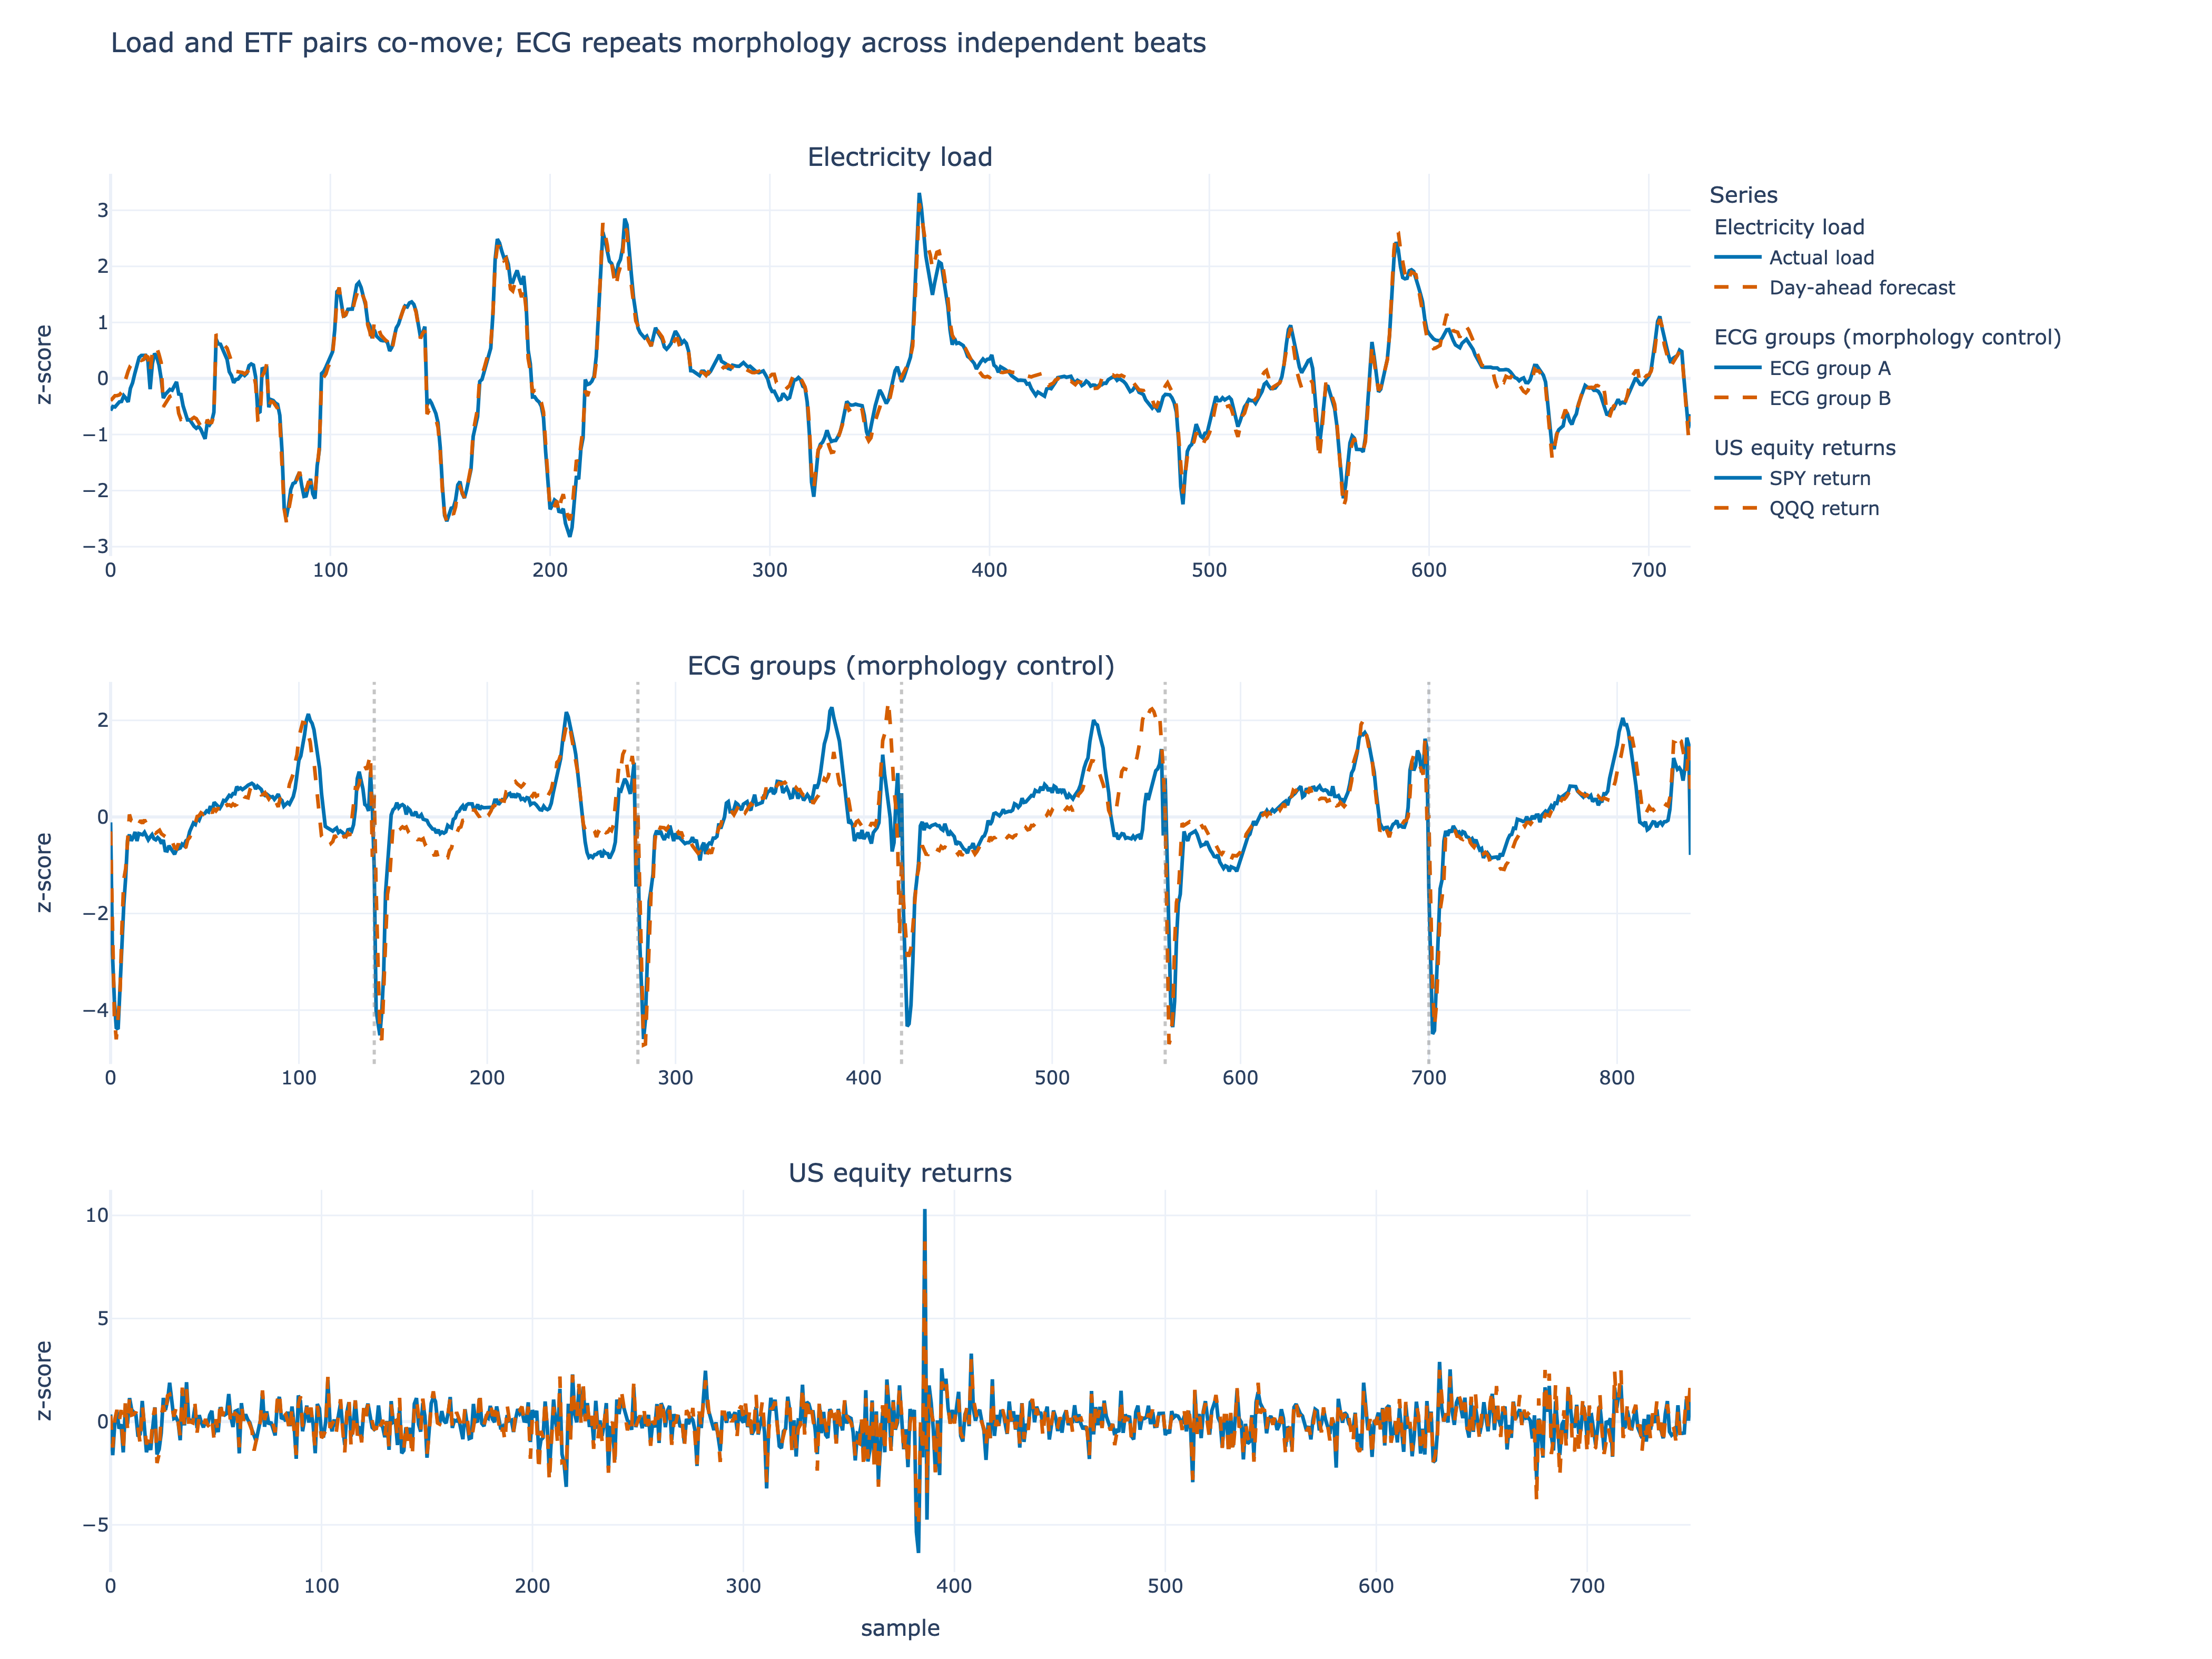

PosixPath('/Users/lopatenko/Desktop/itmo/itmo-ml-2025/tsml/lab-3/figures/paired_series.png')

In [4]:
fig = make_subplots(
    rows=3, cols=1, vertical_spacing=0.09,
    subplot_titles=[pair.name for pair in PAIRS],
)
colors = ["#0072B2", "#D55E00"]
for row, pair in enumerate(PAIRS, start=1):
    fig.add_trace(go.Scatter(
        y=standardize(pair.x), name=pair.x_name, legendgroup=pair.name,
        legendgrouptitle_text=pair.name, line=dict(color=colors[0], width=2.3),
    ), row=row, col=1)
    fig.add_trace(go.Scatter(
        y=standardize(pair.y), name=pair.y_name, legendgroup=pair.name,
        legendgrouptitle_text=pair.name, line=dict(color=colors[1], width=2.3, dash="dash"),
    ), row=row, col=1)
    fig.update_yaxes(title_text="z-score", row=row, col=1)
fig.update_xaxes(title_text="sample", row=3, col=1)
fig.update_layout(
    title="Load and ETF pairs co-move; ECG repeats morphology across independent beats",
    hovermode="x unified",
    legend=dict(title_text="Series", x=1.01, xanchor="left", y=1, yanchor="top", tracegroupgap=12),
)
for boundary in range(140, len(ecg_x), 140):
    fig.add_vline(x=boundary, line_dash="dot", line_color="gray", opacity=0.45, row=2, col=1)
show_and_save(
    fig,
    "paired_series",
    "Three paired standardized series. Load and ETF pairs move closely together; dotted boundaries show that the ECG morphology-control panel concatenates independent beats.",
    height=1050,
    right_margin=330,
)


### First look at the paired series

Before comparing lags, I checked the transformed series with the Augmented Dickey-Fuller test. Its null hypothesis is a unit root, so the small p-values in the table support using these segments as stationary series. The test lag is chosen by AIC. This is important here: cross-correlation and Granger tests applied directly to drifting levels can mistake a common trend for dependence.

The load series pass the check after a 24-hour seasonal difference, and the ETF prices after conversion to log returns. The ECG rows are already normalized beat windows. I use z-scores in the figure only to put all three pairs on a common vertical scale; this does not change their correlations or lag positions.

- **Load:** the 24-hour differences of actual demand and the day-ahead forecast nearly overlap ($r=0.990$). The forecast captures most hour-to-hour changes after the daily cycle is removed, leaving only small forecast errors.
- **ECG:** the two concatenated groups remain strongly correlated at matching within-beat positions ($r=0.876$), even though their beats are independent. This is the first indication that repeated P-QRS-T shape can look like dependence without a shared physiological timeline.
- **ETFs:** SPY and QQQ daily returns have high same-day correlation ($r=0.947$). This is consistent with common market shocks, but the plot alone cannot identify which ETF moves first.


## 2. Cross-correlation findings

I compute Pearson correlation on the overlapping samples at each lag. Positive lags mean that $X$ comes first; negative lags mean that $Y$ comes first. A displaced peak is only a candidate lead-lag relation, because a periodic signal can produce the same pattern.

The dashed reference lines come from 99 circular shifts of $Y$. For each shifted copy I keep the largest absolute correlation over the whole lag range, then take the 95th percentile of those maxima. This gives a threshold for the peak I actually searched for, rather than a pointwise threshold chosen after inspecting the plot. Circular shifting is still an approximation at the wrapped boundary, but it retains the serial structure much better than an independent-sample test.


In [5]:
def cross_correlation(x: np.ndarray, y: np.ndarray, max_lag: int) -> pd.DataFrame:
    '''Pearson correlation at each lag; positive lag means x comes first.'''
    x, y = standardize(x), standardize(y)
    rows = []
    for lag in range(-max_lag, max_lag + 1):
        if lag > 0:
            x_overlap, y_overlap = x[:-lag], y[lag:]
        elif lag < 0:
            x_overlap, y_overlap = x[-lag:], y[:lag]
        else:
            x_overlap, y_overlap = x, y
        correlation = np.corrcoef(x_overlap, y_overlap)[0, 1]
        rows.append({"lag": lag, "correlation": correlation})
    return pd.DataFrame(rows)


cc_curves = {}
cc_limits = {}
cc_rows = []
for pair_index, pair in enumerate(PAIRS):
    curve = cross_correlation(pair.x, pair.y, pair.max_cc_lag)
    cc_curves[pair.name] = curve
    rng = np.random.default_rng(SEED + 200 + pair_index)
    valid_shifts = np.arange(pair.max_cc_lag + 1, len(pair.y) - pair.max_cc_lag)
    shifts = rng.choice(valid_shifts, size=min(99, len(valid_shifts)), replace=False)

    null_maxima = []
    for shift in shifts:
        shifted_y = np.roll(pair.y, int(shift))
        shifted_curve = cross_correlation(pair.x, shifted_y, pair.max_cc_lag)
        null_maxima.append(shifted_curve["correlation"].abs().max())

    reference = float(np.quantile(null_maxima, 0.95))
    cc_limits[pair.name] = reference
    strongest = curve.loc[curve["correlation"].abs().idxmax()]
    strongest_lag = int(strongest["lag"])
    above_threshold = abs(strongest["correlation"]) > reference
    if strongest_lag > 0:
        lag_reading = "X precedes Y"
    elif strongest_lag < 0:
        lag_reading = "Y precedes X"
    else:
        lag_reading = "synchronous"
    if strongest_lag != 0 and not above_threshold:
        lag_reading += " (below threshold)"

    cc_rows.append({
        "pair": pair.name,
        "zero_lag_corr": curve.loc[curve["lag"] == 0, "correlation"].iloc[0],
        "strongest_lag": strongest_lag,
        "strongest_corr": strongest["correlation"],
        "95% circular-shift threshold": reference,
        "exceeds threshold": above_threshold,
        "peak position": lag_reading,
    })

cc_summary = pd.DataFrame(cc_rows)
show_table(cc_summary, "Cross-correlation summary")


+----------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|                                                                      Cross-correlation summary                                                                       |
+---------------------------------+---------------+---------------+----------------+------------------------------+-------------------+--------------------------------+
| pair                            | zero_lag_corr | strongest_lag | strongest_corr | 95% circular-shift threshold | exceeds threshold | peak position                  |
+---------------------------------+---------------+---------------+----------------+------------------------------+-------------------+--------------------------------+
| Electricity load                | 0.9901        | 0             | 0.9901         | 0.3747                       | True              | synchronous        


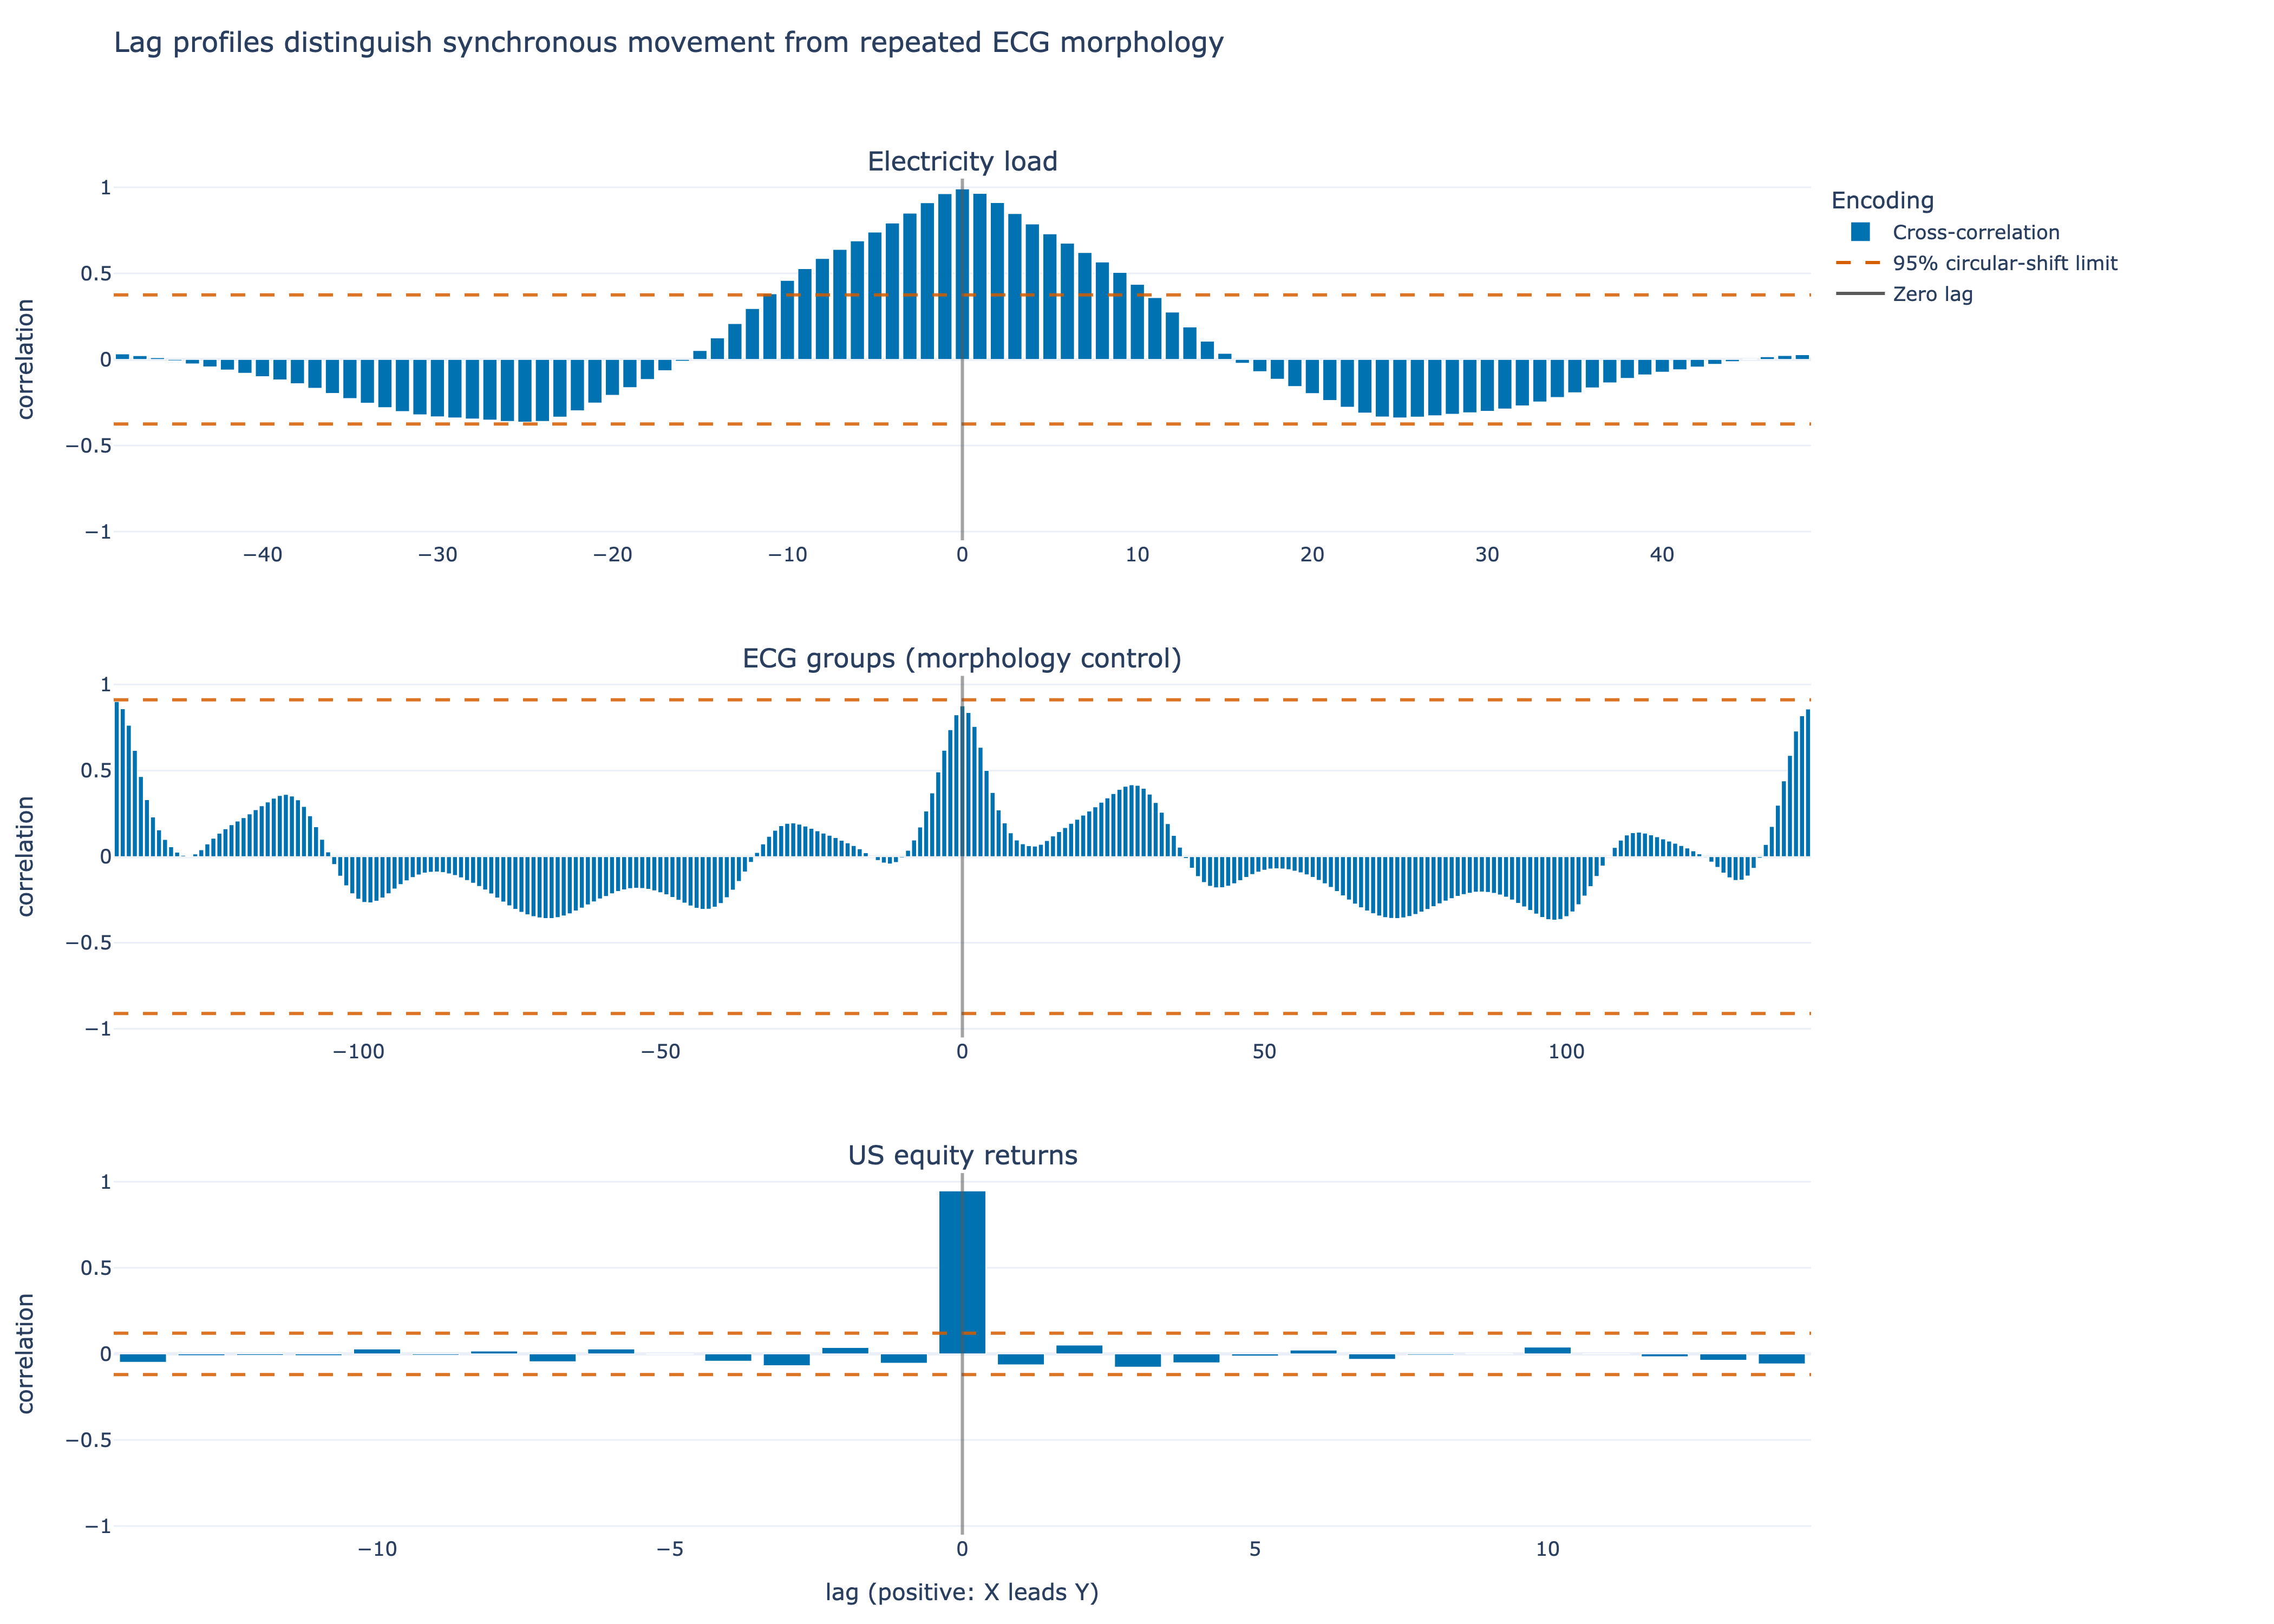

PosixPath('/Users/lopatenko/Desktop/itmo/itmo-ml-2025/tsml/lab-3/figures/cross_correlation.png')

In [6]:
fig = make_subplots(rows=3, cols=1, subplot_titles=[pair.name for pair in PAIRS], vertical_spacing=0.10)
for row, pair in enumerate(PAIRS, start=1):
    curve = cc_curves[pair.name]
    limit = cc_limits[pair.name]
    fig.add_trace(go.Bar(
        x=curve["lag"], y=curve["correlation"], name="Cross-correlation",
        marker_color="#0072B2", showlegend=row == 1,
    ), row=row, col=1)
    for value in (-limit, limit):
        fig.add_hline(y=value, line_dash="dash", line_color="#D55E00", opacity=0.85, row=row, col=1)
    fig.add_vline(x=0, line_color="#595959", opacity=0.55, row=row, col=1)
    fig.update_yaxes(title_text="correlation", range=[-1.05, 1.05], row=row, col=1)

fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines", name="95% circular-shift limit",
                         line=dict(color="#D55E00", width=2, dash="dash")), row=1, col=1)
fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines", name="Zero lag",
                         line=dict(color="#595959", width=2)), row=1, col=1)
fig.update_xaxes(title_text="lag (positive: X leads Y)", row=3, col=1)
fig.update_layout(
    title="Lag profiles distinguish synchronous movement from repeated ECG morphology",
    legend=dict(title_text="Encoding", x=1.01, xanchor="left", y=1, yanchor="top"),
)
show_and_save(
    fig,
    "cross_correlation",
    "Cross-correlation bars across positive and negative lags for load, ECG morphology-control groups, and ETF returns. Dashed lines are autocorrelation-preserving circular-shift thresholds.",
    height=1000,
    right_margin=285,
)


### Reading the lag profiles

- **Load:** the maximum is at lag 0 ($r=0.990$), well above the circular-shift threshold of 0.375. The peak is centered at zero rather than displaced to one side, so the dominant relation is synchronous tracking, not a lead-lag effect.
- **ECG:** the largest coefficient occurs at lag $-140$ ($r=0.901$), exactly one 140-sample beat apart. It remains below the 0.911 shift threshold. The apparent displacement therefore follows the repeated beat length and is not evidence that one independently sampled group precedes the other.
- **ETFs:** the maximum is again at lag 0 ($r=0.947$ versus a 0.120 threshold). Correlation falls sharply away from zero, which supports a common same-day market response rather than a persistent daily lead by SPY or QQQ.

Thus, cross-correlation identifies strong synchrony for load and ETFs, while the ECG result demonstrates how periodic morphology can create an apparently meaningful lag.


## 3. Granger findings

For each direction I compare a linear model of $Y$ from its own past with a second model that also contains past $X$. The SSR F-test asks whether those added $X$ terms reduce the residual error. `statsmodels` expects the columns as `[effect, cause]`, which is why that order is explicit in the code.

I test five lag orders per direction: up to one day for load, 20 samples for ECG and two trading weeks for the ETFs. The reported decision uses Holm-adjusted p-values within each pair and direction. I leave the raw p-values in the table because they show which apparent results disappear once the lag search is accounted for. Throughout the notebook, “Granger-causes” is used in its predictive sense: past $X$ adds information about future $Y$ in this linear model.


In [7]:
def granger_table(pair: SeriesPair) -> pd.DataFrame:
    '''Run the requested lag orders in both directions for one pair.'''
    rows = []
    directions = [
        (pair.x_name, pair.y_name, pair.x, pair.y),
        (pair.y_name, pair.x_name, pair.y, pair.x),
    ]
    max_lag = max(pair.granger_lags)
    for cause_name, effect_name, cause, effect in directions:
        try:
            fitted = grangercausalitytests(
                np.column_stack([standardize(effect), standardize(cause)]),
                maxlag=max_lag,
            )
            for lag in pair.granger_lags:
                f_stat, p_value, _, _ = fitted[lag][0]["ssr_ftest"]
                rows.append({
                    "pair": pair.name,
                    "direction": f"{cause_name} → {effect_name}",
                    "lag": lag,
                    "F": f_stat,
                    "p_value": p_value,
                    "p<0.05": p_value < 0.05,
                })
        except Exception as error:
            for lag in pair.granger_lags:
                rows.append({
                    "pair": pair.name,
                    "direction": f"{cause_name} → {effect_name}",
                    "lag": lag,
                    "F": np.nan,
                    "p_value": np.nan,
                    "p<0.05": False,
                    "error": type(error).__name__,
                })
    return pd.DataFrame(rows)


granger_results = pd.concat([granger_table(pair) for pair in PAIRS], ignore_index=True)


def holm_adjust(values: pd.Series) -> np.ndarray:
    if values.isna().any():
        return np.full(len(values), np.nan)
    return multipletests(values, method="holm")[1]


granger_results["p_holm"] = granger_results.groupby(["pair", "direction"])["p_value"].transform(
    holm_adjust
)
granger_results["significant_holm"] = granger_results["p_holm"] < 0.05
show_table(granger_results, "Granger SSR F-tests", precision=5)


+-------------------------------------------------------------------------------------------------------------------------------------+
|                                                         Granger SSR F-tests                                                         |
+---------------------------------+----------------------------------+-----+----------+---------+--------+---------+------------------+
| pair                            | direction                        | lag | F        | p_value | p<0.05 | p_holm  | significant_holm |
+---------------------------------+----------------------------------+-----+----------+---------+--------+---------+------------------+
| Electricity load                | Actual load → Day-ahead forecast | 1   | 1.82353  | 0.17732 | False  | 0.17732 | False            |
| Electricity load                | Actual load → Day-ahead forecast | 2   | 7.85913  | 0.00042 | True   | 0.00210 | True             |
| Electricity load                | Actual load 


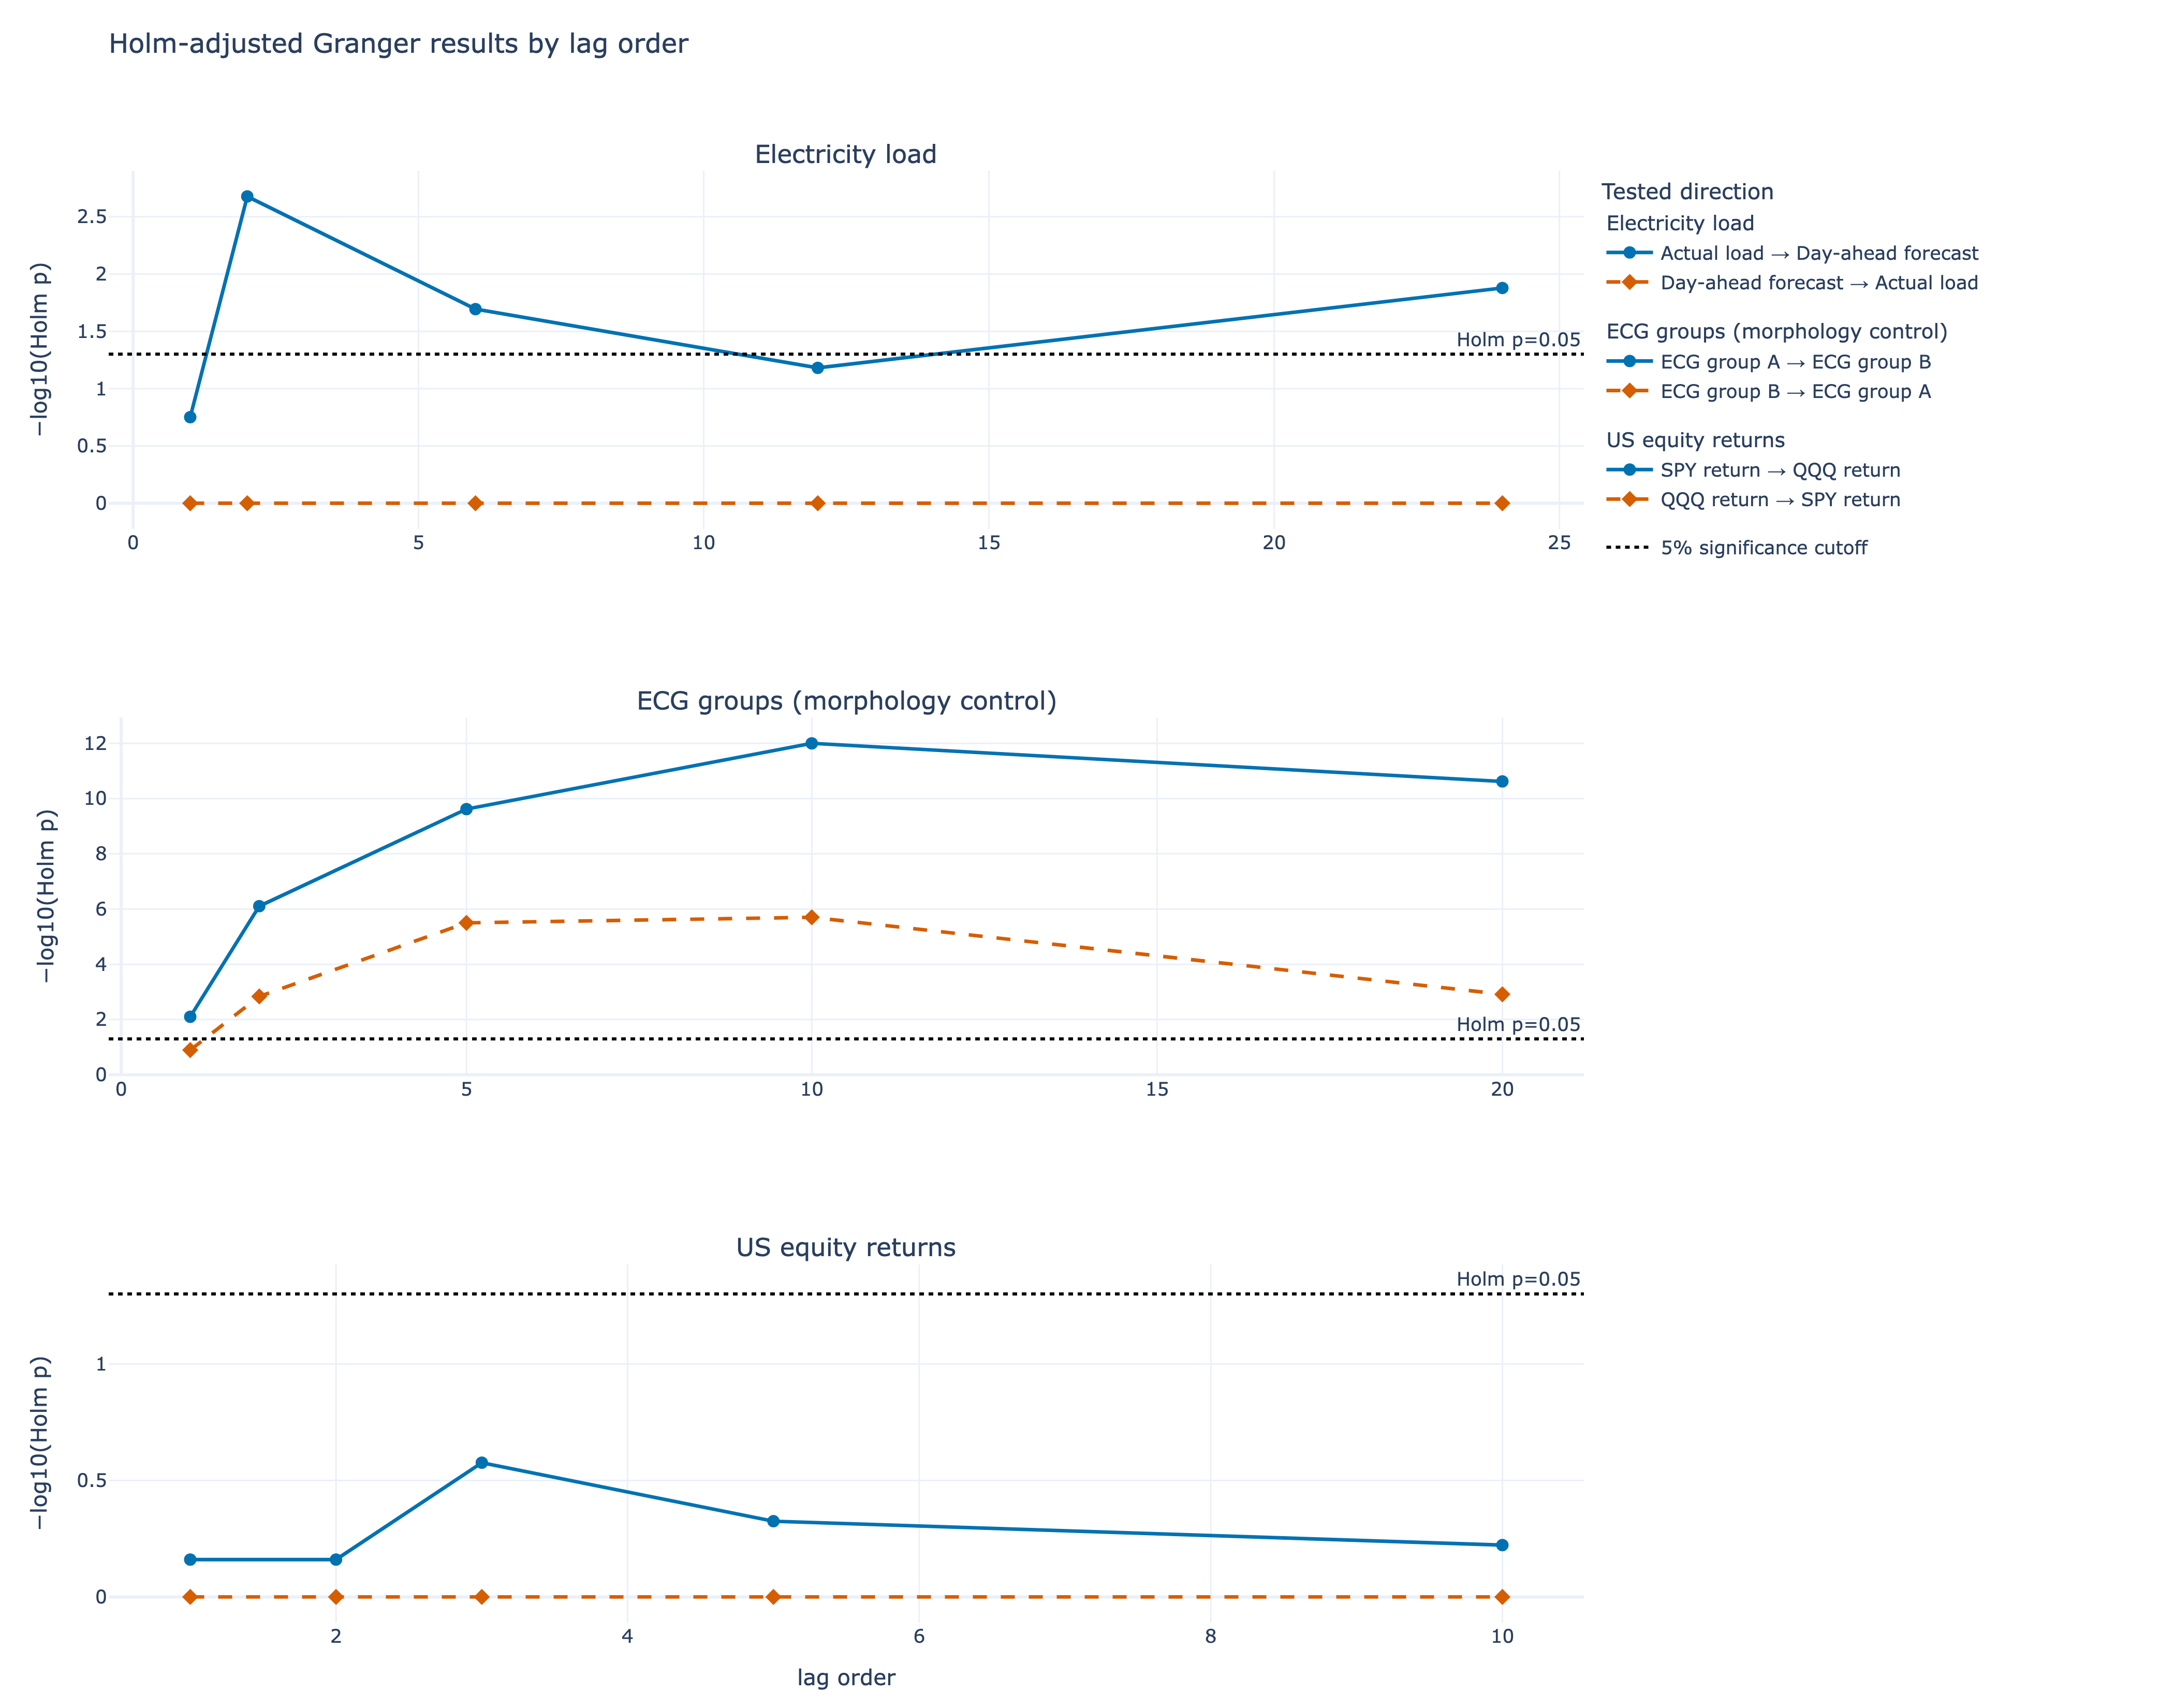

PosixPath('/Users/lopatenko/Desktop/itmo/itmo-ml-2025/tsml/lab-3/figures/granger_pvalues.png')

In [8]:
fig = make_subplots(
    rows=3, cols=1, vertical_spacing=0.13,
    subplot_titles=[pair.name for pair in PAIRS],
)
palette = ["#0072B2", "#D55E00"]
for row, pair in enumerate(PAIRS, start=1):
    panel = granger_results[granger_results["pair"] == pair.name]
    directions = [f"{pair.x_name} → {pair.y_name}", f"{pair.y_name} → {pair.x_name}"]
    for direction_index, (color, direction) in enumerate(zip(palette, directions)):
        values = panel[panel["direction"] == direction]
        score = -np.log10(values["p_holm"].clip(lower=1e-12))
        line_style = "solid" if direction_index == 0 else "dash"
        marker_symbol = "circle" if direction_index == 0 else "diamond"
        trace = go.Scatter(
            x=values["lag"], y=score, mode="lines+markers", name=direction,
            legendgroup=pair.name, legendgrouptitle_text=pair.name,
            line=dict(color=color, width=2.3, dash=line_style), marker=dict(symbol=marker_symbol, size=8),
        )
        fig.add_trace(trace, row=row, col=1)
    fig.add_hline(y=-np.log10(0.05), line_dash="dot", line_color="black", annotation_text="Holm p=0.05", row=row, col=1)
    fig.update_yaxes(title_text="−log10(Holm p)", row=row, col=1)

fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines", name="5% significance cutoff",
                         line=dict(color="black", width=2, dash="dot")), row=1, col=1)
fig.update_xaxes(title_text="lag order", row=3, col=1)
fig.update_layout(
    title="Holm-adjusted Granger results by lag order",
    legend=dict(title_text="Tested direction", x=1.01, xanchor="left", y=1, yanchor="top", tracegroupgap=12),
)
show_and_save(
    fig,
    "granger_pvalues",
    "Negative log10 Holm-adjusted Granger p-values across lag orders in both directions for each pair. Points above the dotted threshold are significant at 5 percent after correction.",
    height=1100,
    right_margin=380,
)


### Reading the Granger results

- **Load:** past actual load improves prediction of the forecast series at lags 2, 6 and 24 after Holm correction ($p_{Holm}=0.0021$, 0.0202 and 0.0132). The reverse direction is not significant at any tested lag. This asymmetry is consistent with the forecast being built from previously observed demand patterns, especially the daily cycle. It should not be read as realized future demand changing a forecast that was already issued.
- **ECG:** both directions are significant at most tested lags, but the two groups have no common clock. Their repeated waveforms and the artificial boundaries between concatenated beats make samples from one group useful for predicting similar positions in the other. Here the Granger test detects reusable morphology, not physiological influence.
- **ETFs:** neither direction survives correction; the smallest adjusted value is 0.265. The strong same-day correlation therefore does not translate into stable incremental predictability at daily lags.

Only the load pair contains an interpretable temporal asymmetry, and even there the result is predictive rather than proof of a causal mechanism.


## 4. Convergent Cross Mapping (CCM)

### What I mean by “skill”

Here, skill is simply the Pearson correlation between observed values and reconstructed values. **Simplex skill**, $\rho(Y_{t+1},\hat{Y}_{t+1})$, tells me whether a proposed embedding predicts its own next observation. **Cross-map skill**, $\rho(X_t,\hat{X}_t)$, tells me whether the state of the other series contains enough information to reconstruct $X$. It runs from $-1$ to $1$ and is not an accuracy percentage. Since correlation ignores shifts and rescaling, a high value means that the reconstructed pattern follows the observations; it does not mean that the amplitudes are perfectly calibrated.

### Implementation note

I wrote out the CCM calculation rather than hiding it behind a package call. For an effect series $Y$, the delay vectors are

$$M_Y(t)=[Y_t,Y_{t-\tau},\ldots,Y_{t-(E-1)\tau}].$$

I try $E=2,3,4$ and $\tau=1,2,3$, retaining the combination with the best one-step simplex skill. To test $X\rightarrow Y$, I then find the $E+1$ nearest neighbours on the **$Y$ manifold** and use their matching $X$ values to reconstruct $X_t$. The direction can look backwards at first, but this is the CCM argument: if $X$ has influenced $Y$, traces of $X$ should be present in the reconstructed state of $Y$.

Neighbour weights decay as $\exp(-d_i/d_{min})$. I exclude nearby time points with a Theiler window—24 hours for load, one beat for ECG and five trading days for the ETFs—so that a point is not reconstructed from its almost identical temporal neighbours. The calculation is repeated at five library sizes, with six random libraries at the intermediate sizes. The error bars show the variation across those draws; `skill_growth` is the difference between the first and last mean skill. A convincing CCM pattern should gain skill as the library grows, not merely finish at a high value.

The surrogate check repeats the full-library calculation after 39 circular shifts of the putative cause series. Its p-value is $(1+\#\{\rho_{null}\geq\rho_{obs}\})/40$, so the smallest possible value is 0.025. This implementation is deliberately compact: embedding selection and evaluation use the same data segment, the intermediate libraries are random subsets rather than contiguous blocks, and the shift null cannot represent every shared external driver. I therefore treat strong bidirectional skill with little growth as evidence of shared state information, not automatic evidence of two-way causation.


In [9]:
def delay_embedding(values: np.ndarray, dimension: int, tau: int) -> np.ndarray:
    '''Construct [x(t), x(t-tau), ...] after standardizing the series.'''
    values = standardize(values)
    first_complete_state = (dimension - 1) * tau
    coordinates = [values[first_complete_state - step * tau : len(values) - step * tau] for step in range(dimension)]
    return np.column_stack(coordinates)


def nearest_neighbors(distance_row: np.ndarray, candidates: np.ndarray, count: int) -> tuple[np.ndarray, np.ndarray]:
    '''Return simplex neighbours and exponential distance weights.'''
    positions = np.argpartition(distance_row[candidates], count - 1)[:count]
    neighbors = candidates[positions]
    local_distances = distance_row[neighbors]
    distance_scale = max(float(local_distances.min()), 1e-12)
    weights = np.exp(-local_distances / distance_scale)
    return neighbors, weights / weights.sum()


def simplex_prediction_skill(values: np.ndarray, dimension: int, tau: int, theiler: int) -> float:
    '''One-step self-prediction used only to choose E and tau.'''
    manifold = delay_embedding(values, dimension, tau)[:-1]
    next_values = standardize(values)[(dimension - 1) * tau + 1 :]
    distances = cdist(manifold, manifold)
    all_indices = np.arange(len(next_values))
    observed, predicted = [], []

    for point in all_indices:
        candidates = all_indices[np.abs(all_indices - point) > theiler]
        if len(candidates) < dimension + 1:
            continue
        neighbors, weights = nearest_neighbors(distances[point], candidates, dimension + 1)
        observed.append(float(next_values[point]))
        predicted.append(float(weights @ next_values[neighbors]))

    return float(np.corrcoef(observed, predicted)[0, 1])


def select_embedding(values: np.ndarray, theiler: int) -> tuple[int, int, float]:
    tried = []
    for dimension in (2, 3, 4):
        for tau in (1, 2, 3):
            skill = simplex_prediction_skill(values, dimension, tau, theiler)
            tried.append((dimension, tau, skill))
    return max(tried, key=lambda result: result[2])


def cross_map_skill(cause_values: np.ndarray, manifold_distances: np.ndarray, library_indices: np.ndarray, dimension: int, theiler: int) -> float:
    '''Reconstruct the putative cause from neighbours on the effect manifold.'''
    observed, reconstructed = [], []
    for point in range(len(cause_values)):
        candidates = library_indices[(library_indices != point) & (np.abs(library_indices - point) > theiler)]
        if len(candidates) < dimension + 1:
            continue
        neighbors, weights = nearest_neighbors(manifold_distances[point], candidates, dimension + 1)
        observed.append(float(cause_values[point]))
        reconstructed.append(float(weights @ cause_values[neighbors]))

    if len(observed) < 4:
        return np.nan
    return float(np.corrcoef(observed, reconstructed)[0, 1])


def ccm_convergence_curve(cause: np.ndarray, effect: np.ndarray, seed: int, dimension: int, tau: int, theiler: int, repeats: int = 6) -> pd.DataFrame:
    effect_manifold = delay_embedding(effect, dimension, tau)
    manifold_distances = cdist(effect_manifold, effect_manifold)
    cause_values = standardize(cause)[(dimension - 1) * tau :]
    n_points = len(cause_values)

    minimum_size = max(60, 2 * theiler + dimension + 2)
    library_sizes = np.unique(np.linspace(min(minimum_size, n_points), n_points, 5, dtype=int))
    rng = np.random.default_rng(seed)
    rows = []

    for library_size in library_sizes:
        repeats_at_size = 1 if library_size == n_points else repeats
        for repeat in range(repeats_at_size):
            if library_size == n_points:
                library = np.arange(n_points)
            else:
                library = np.sort(rng.choice(n_points, size=library_size, replace=False))
            skill = cross_map_skill(cause_values, manifold_distances, library, dimension, theiler)
            rows.append({"library_size": int(library_size), "repeat": repeat + 1, "skill": skill})
    return pd.DataFrame(rows)


ccm_parts = []
embedding_rows = []
surrogate_rows = []
for pair_index, pair in enumerate(PAIRS):
    directions = [
        (pair.x_name, pair.y_name, pair.x, pair.y),
        (pair.y_name, pair.x_name, pair.y, pair.x),
    ]
    for direction_index, (cause_name, effect_name, cause, effect) in enumerate(directions):
        direction = f"{cause_name} → {effect_name}"
        dimension, tau, selection_skill = select_embedding(effect, pair.ccm_theiler)
        curve = ccm_convergence_curve(cause, effect, seed=SEED + 10 * pair_index + direction_index, dimension=dimension, tau=tau, theiler=pair.ccm_theiler)
        curve["pair"] = pair.name
        curve["direction"] = direction
        curve["E"] = dimension
        curve["tau"] = tau
        ccm_parts.append(curve)
        embedding_rows.append({
            "pair": pair.name,
            "effect manifold": effect_name,
            "E": dimension,
            "tau": tau,
            "simplex skill": selection_skill,
            "Theiler window": pair.ccm_theiler,
        })

        effect_manifold = delay_embedding(effect, dimension, tau)
        manifold_distances = cdist(effect_manifold, effect_manifold)
        cause_values = standardize(cause)[(dimension - 1) * tau :]
        full_library = np.arange(len(cause_values))
        observed_skill = cross_map_skill(cause_values, manifold_distances, full_library, dimension, pair.ccm_theiler)

        rng = np.random.default_rng(SEED + 100 + 10 * pair_index + direction_index)
        valid_shifts = np.arange(pair.ccm_theiler + 1, len(cause) - pair.ccm_theiler)
        shifts = rng.choice(valid_shifts, size=min(39, len(valid_shifts)), replace=False)
        null_skills = []
        for shift in shifts:
            shifted_cause = standardize(np.roll(cause, int(shift)))[(dimension - 1) * tau :]
            null_skill = cross_map_skill(shifted_cause, manifold_distances, full_library, dimension, pair.ccm_theiler)
            null_skills.append(null_skill)

        more_extreme = sum(skill >= observed_skill for skill in null_skills)
        surrogate_p = (1 + more_extreme) / (len(null_skills) + 1)
        surrogate_rows.append({"pair": pair.name, "direction": direction, "surrogate p-value": surrogate_p})

ccm_results = pd.concat(ccm_parts, ignore_index=True)
embedding_selection = pd.DataFrame(embedding_rows)
ccm_surrogates = pd.DataFrame(surrogate_rows)
show_table(embedding_selection, "CCM embedding selection")
ccm_summary = (
    ccm_results.groupby(["pair", "direction", "E", "tau", "library_size"], as_index=False)
    .agg(mean_skill=("skill", "mean"), std_skill=("skill", "std"))
)

ccm_rows = []
for (pair_name, direction), group in ccm_summary.groupby(["pair", "direction"]):
    group = group.sort_values("library_size")
    ccm_rows.append({
        "pair": pair_name,
        "direction": direction,
        "initial_skill": group.iloc[0]["mean_skill"],
        "final_skill": group.iloc[-1]["mean_skill"],
        "skill_growth": group.iloc[-1]["mean_skill"] - group.iloc[0]["mean_skill"],
        "E": int(group.iloc[0]["E"]),
        "tau": int(group.iloc[0]["tau"]),
    })
ccm_direction_summary = pd.DataFrame(ccm_rows).merge(ccm_surrogates, on=["pair", "direction"], how="left")
ccm_direction_summary["surrogate p<0.05"] = ccm_direction_summary["surrogate p-value"] < 0.05
show_table(ccm_direction_summary, "CCM reconstruction summary")


+-------------------------------------------------------------------------------------------------+
|                                     CCM embedding selection                                     |
+---------------------------------+--------------------+---+-----+---------------+----------------+
| pair                            | effect manifold    | E | tau | simplex skill | Theiler window |
+---------------------------------+--------------------+---+-----+---------------+----------------+
| Electricity load                | Day-ahead forecast | 2 | 1   | 0.9732        | 24             |
| Electricity load                | Actual load        | 2 | 1   | 0.9738        | 24             |
| ECG groups (morphology control) | ECG group B        | 2 | 1   | 0.9419        | 140            |
| ECG groups (morphology control) | ECG group A        | 2 | 1   | 0.9347        | 140            |
| US equity returns               | QQQ return         | 2 | 3   | 0.1131        | 5              |



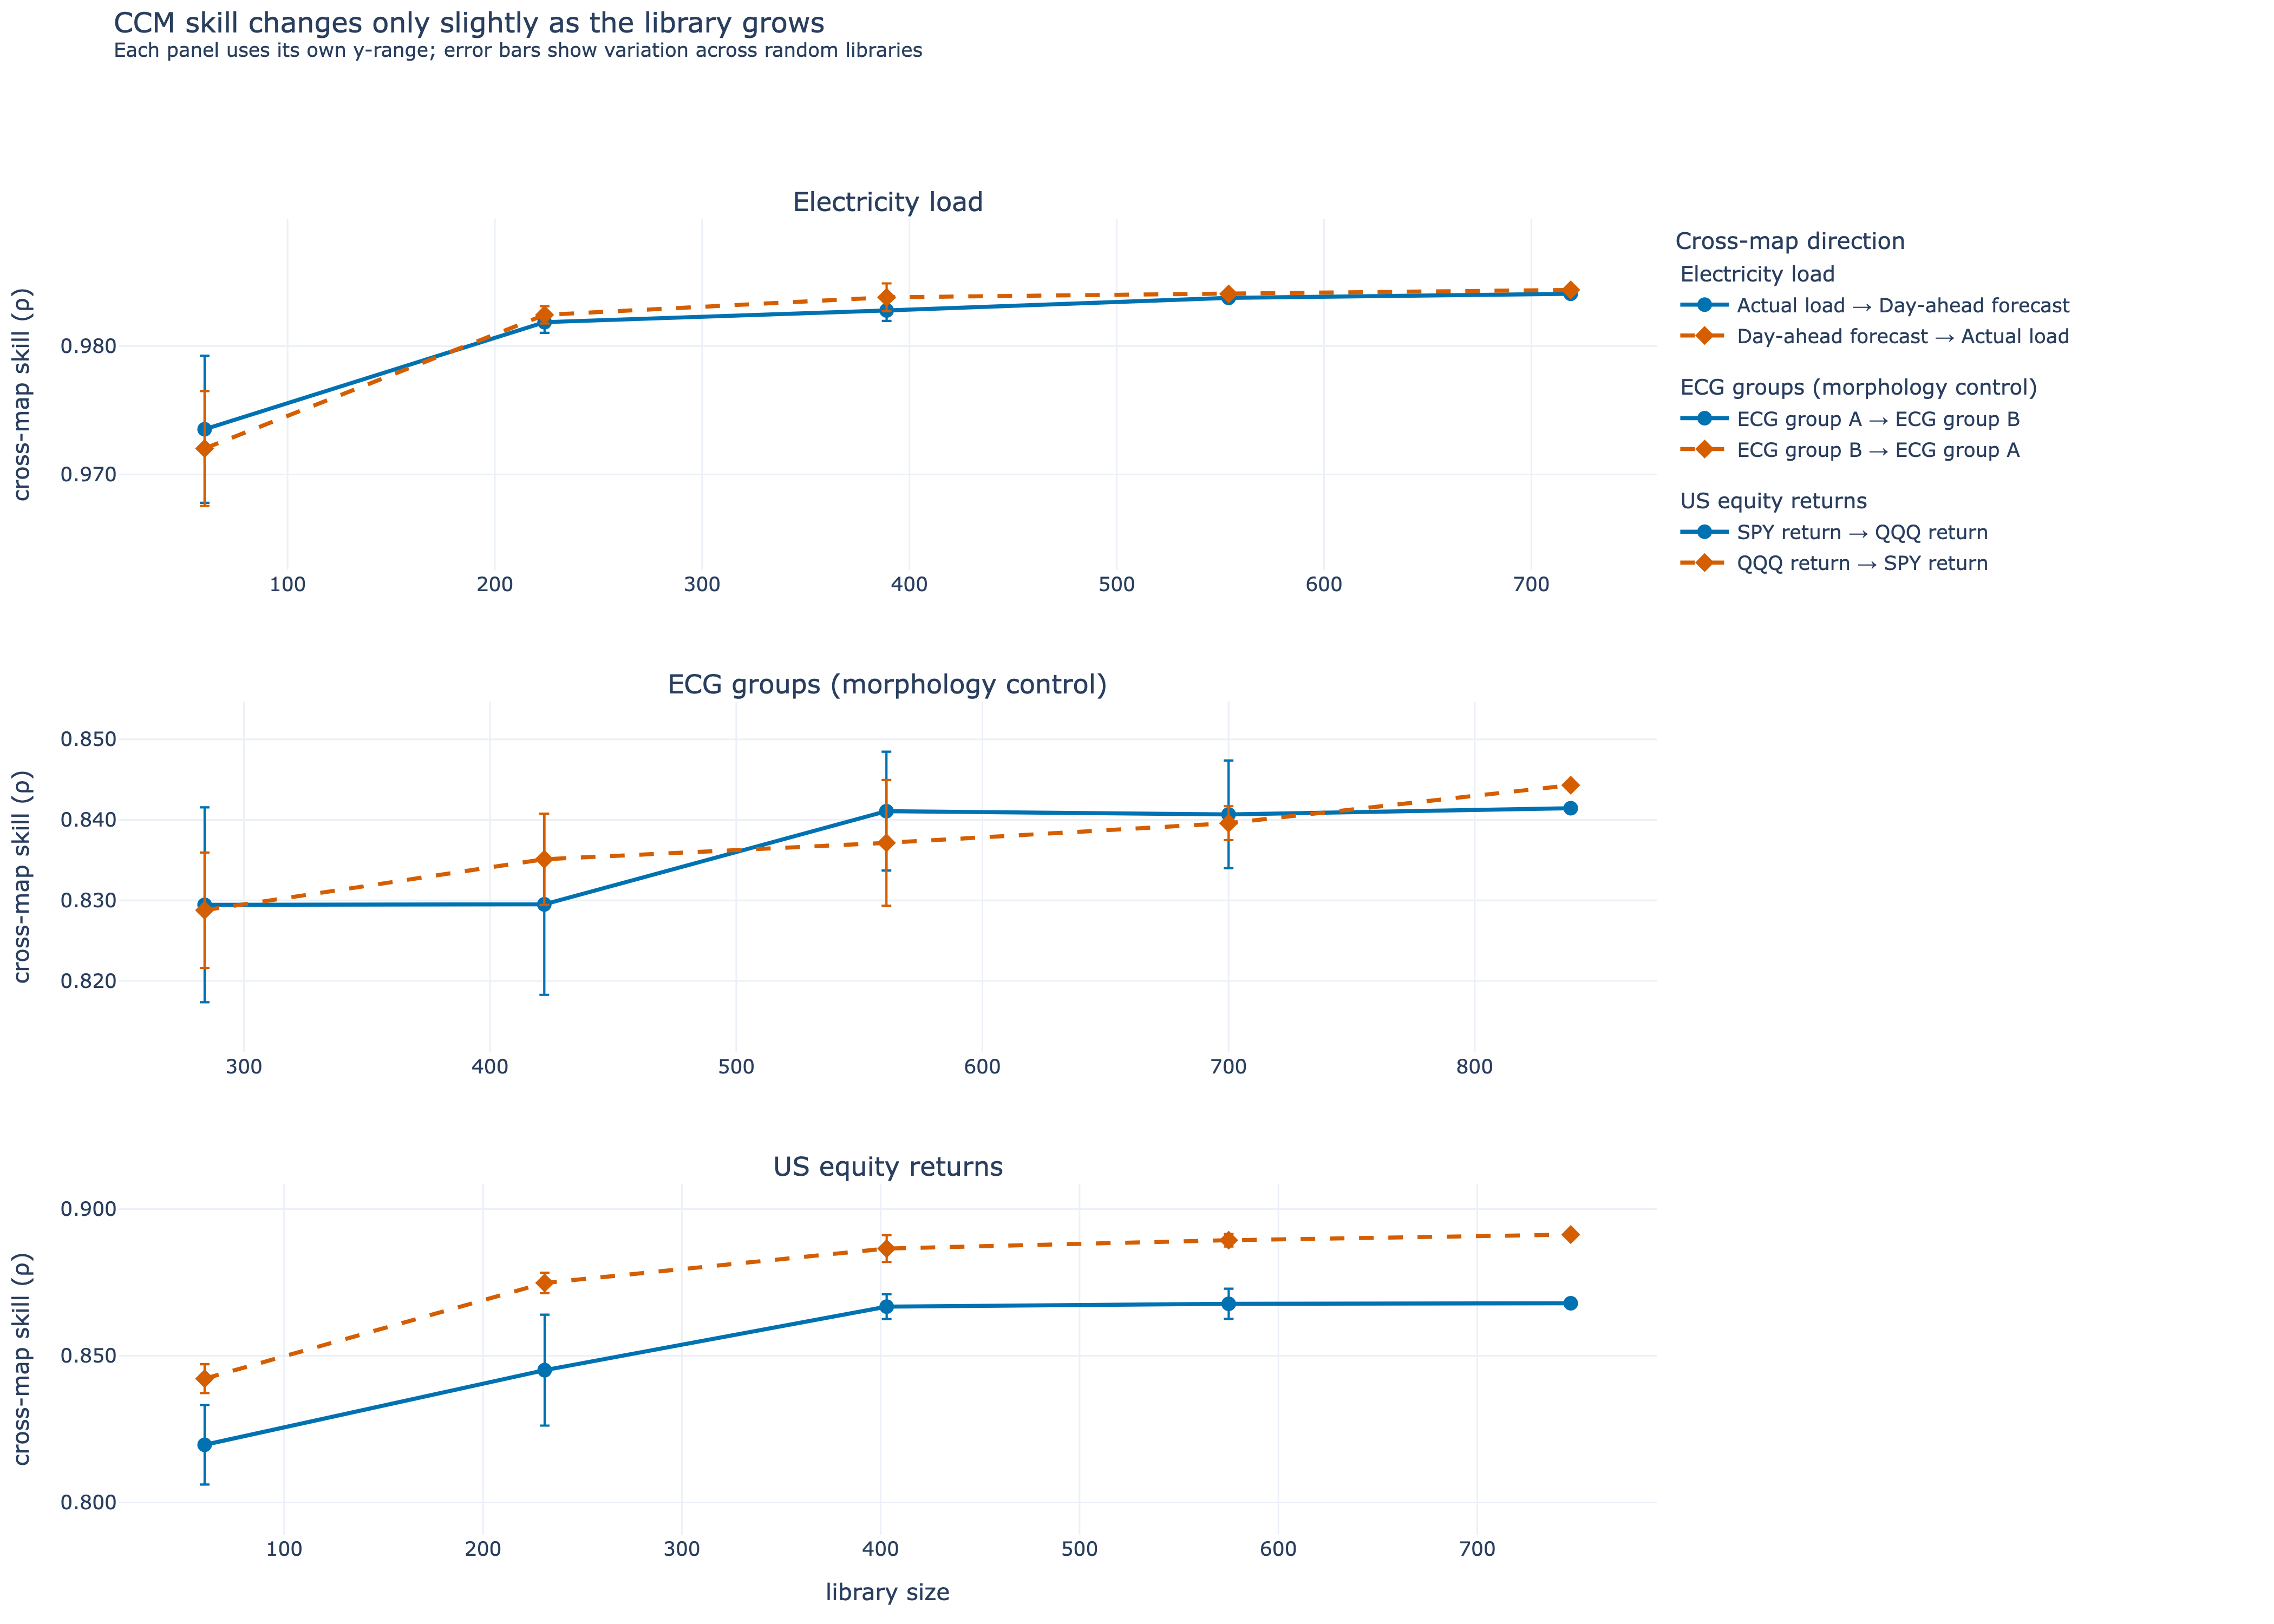

PosixPath('/Users/lopatenko/Desktop/itmo/itmo-ml-2025/tsml/lab-3/figures/ccm_convergence.png')

In [10]:
fig = make_subplots(
    rows=3, cols=1, vertical_spacing=0.10,
    subplot_titles=[pair.name for pair in PAIRS],
)
palette = ["#0072B2", "#D55E00"]
for row, pair in enumerate(PAIRS, start=1):
    panel = ccm_summary[ccm_summary["pair"] == pair.name]
    directions = [f"{pair.x_name} → {pair.y_name}", f"{pair.y_name} → {pair.x_name}"]
    for direction_index, (color, direction) in enumerate(zip(palette, directions)):
        values = panel[panel["direction"] == direction].sort_values("library_size")
        line_style = "solid" if direction_index == 0 else "dash"
        marker_symbol = "circle" if direction_index == 0 else "diamond"
        trace = go.Scatter(
            x=values["library_size"], y=values["mean_skill"], mode="lines+markers", name=direction,
            legendgroup=pair.name, legendgrouptitle_text=pair.name,
            line=dict(color=color, width=2.5, dash=line_style), marker=dict(symbol=marker_symbol, size=9),
            error_y=dict(type="data", array=values["std_skill"].fillna(0), color=color, thickness=1.4, width=3),
        )
        fig.add_trace(trace, row=row, col=1)

    uncertainty = panel["std_skill"].fillna(0)
    lower = float((panel["mean_skill"] - uncertainty).min())
    upper = float((panel["mean_skill"] + uncertainty).max())
    padding = max(0.005, (upper - lower) * 0.2)
    fig.update_yaxes(title_text="cross-map skill (ρ)", range=[max(-1, lower - padding), min(1, upper + padding)],
                     tickformat=".3f", nticks=5, row=row, col=1)
fig.update_xaxes(title_text="library size", row=3, col=1)
fig.update_layout(
    title="CCM skill changes only slightly as the library grows<br><sup>Each panel uses its own y-range; error bars show variation across random libraries</sup>",
    legend=dict(title_text="Cross-map direction", x=1.01, xanchor="left", y=1, yanchor="top", tracegroupgap=12),
)
show_and_save(
    fig,
    "ccm_convergence",
    "CCM cross-map skill versus library size in both directions for load, ECG morphology-control groups, and ETF returns. Panel-specific y-ranges reveal small differences between directions; error bars show variation across random libraries and temporal neighbors are excluded.",
    height=1000,
    top_margin=135,
    right_margin=380,
)


### Reading the CCM curves

- **Load:** both directions already have cross-map skill above 0.97 at the smallest library and finish near 0.984; growth is only 0.011–0.012. This is strong state-space redundancy, but the almost identical bidirectional curves do not resolve direction. Actual and forecast load encode the same demand regime and share calendar and weather structure.
- **ECG:** the two directions finish at 0.841 and 0.844 with little growth. Despite surrogate $p=0.025$, this cannot represent interaction between independently sampled beat groups. CCM reconstructs the repeated waveform geometry, confirming that high cross-map skill can be produced by common morphology.
- **ETFs:** skill rises by about 0.05 and reaches 0.891 for QQQ $\rightarrow$ SPY and 0.868 for SPY $\rightarrow$ QQQ. The modest difference is small relative to the strong reconstruction in both directions and the absence of Granger evidence. A shared market state is the more defensible explanation than a stable directional link.

The reported $p=0.025$ is the minimum possible with 39 surrogates. It means that none of the sampled circular shifts matched the observed skill; it is not a precise measure of effect strength.


### Cross-method synthesis

**Electricity load** is the only pair for which the methods produce a coherent temporal asymmetry: cross-correlation shows near-perfect simultaneous tracking, Granger adds evidence that past actual load improves prediction of the forecast series, and CCM shows that both series encode essentially the same system state. The result describes the forecasting process and its shared inputs; it does not establish that one measured series physically causes the other.

**The ECG pair is a deliberate stress test.** Its one-beat cross-correlation displacement fails the shift threshold, yet Granger and CCM are highly significant. Because the groups consist of independent beats, those detections must come from repeated waveform shape and concatenation boundaries. This disagreement is useful: agreement between sophisticated metrics is still unconvincing when the data construction rules out the proposed interaction.

**SPY and QQQ are coupled contemporaneously, not directionally at the tested daily scale.** Their zero-lag correlation is strong, but neither Granger direction survives multiplicity correction and CCM is strong both ways. The combined evidence is most consistent with both ETFs responding to the same market-wide information.


## 6. Dynamic Time Warping on MIT-BIH ECG records

For the alignment example I use records 100 and 101 from the [MIT-BIH Arrhythmia Database](https://physionet.org/content/mitdb/1.0.0/), sampled at 360 Hz. The CSV copies are also available from the linked [Kaggle dataset](https://www.kaggle.com/datasets/mondejar/mitbih-database) and [MIT course mirror](https://courses.csail.mit.edu/18.337/2017/projects/morales_manuel/datasets/ecg_data/MIT-BIH-arrhythmia-database/).

I detect R peaks on the standardized primary lead, require at least 180 samples between candidates, and take the same 240-sample window around a valid peak from each record: 90 samples before and 150 after. DTW then fills the accumulated-cost matrix

$$D_{i,j}=(x_i-y_j)^2+\min(D_{i-1,j},D_{i,j-1},D_{i-1,j-1}).$$

and backtracks from its final cell to obtain the lowest-cost monotone path. Horizontal or vertical steps let one beat advance while the other stays in place, which is how DTW represents local stretching. I restrict the path to 60 samples around the diagonal so that unrelated parts of the cardiac cycle cannot be matched freely. The normalized distance is the square root of total path cost divided by $\sqrt{\text{path length}}$. For the warped RMSE, all record-101 samples assigned to one record-100 position are averaged first.


In [12]:
MIT_MIRROR = "https://courses.csail.mit.edu/18.337/2017/projects/morales_manuel/datasets/ecg_data/MIT-BIH-arrhythmia-database"


def find_mit_record(record: str) -> Path:
    local_candidates = [
        DATA_DIR / f"{record}.csv",
        DATA_DIR / "mitbih" / f"{record}.csv",
        LAB_DIR / f"{record}.csv",
    ]
    for path in local_candidates:
        if path.exists() and path.stat().st_size > 0:
            return path
    return download(f"{MIT_MIRROR}/{record}.csv", DATA_DIR / f"{record}.csv")


def load_mit_signal(record: str, limit: int = 12000) -> np.ndarray:
    frame = pd.read_csv(find_mit_record(record), header=None, nrows=limit)
    if frame.shape[1] < 3:
        raise ValueError(f"record {record} must contain time and two ECG leads")
    signal = pd.to_numeric(frame.iloc[:, 1], errors="coerce").dropna().to_numpy(dtype=float)
    if len(signal) < 1000:
        raise ValueError(f"record {record} is too short")
    return signal


def select_beat(signal: np.ndarray, before: int = 90, after: int = 150) -> tuple[np.ndarray, int]:
    '''Select a complete beat around an R peak and return it as z-scores.'''
    z = standardize(signal)
    peaks, _ = find_peaks(z, distance=180, prominence=0.8)
    valid = peaks[(peaks > before) & (peaks < len(z) - after)]
    if len(valid) == 0:
        peak = int(np.argmax(z[before:-after]) + before)
    else:
        peak = int(valid[min(3, len(valid) - 1)])
    return standardize(signal[peak - before : peak + after]), peak


signal_100 = load_mit_signal("100")
signal_101 = load_mit_signal("101")
beat_100, peak_100 = select_beat(signal_100)
beat_101, peak_101 = select_beat(signal_101)

mit_overview = pd.DataFrame([
    {"record": "100", "loaded_samples": len(signal_100), "selected_peak": peak_100, "beat_samples": len(beat_100)},
    {"record": "101", "loaded_samples": len(signal_101), "selected_peak": peak_101, "beat_samples": len(beat_101)},
])
show_table(mit_overview, "Selected MIT-BIH ECG fragments")


+--------------------------------------------------------+
|             Selected MIT-BIH ECG fragments             |
+--------+----------------+---------------+--------------+
| record | loaded_samples | selected_peak | beat_samples |
+--------+----------------+---------------+--------------+
| 100    | 12000          | 1231          | 240          |
| 101    | 12000          | 1368          | 240          |
+--------+----------------+---------------+--------------+


In [13]:
def dynamic_time_warping(x: np.ndarray, y: np.ndarray, window: Optional[int] = None):
    '''Compute a window-constrained DTW distance, path and cost matrix.'''
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    n, m = len(x), len(y)
    window = max(abs(n - m), window if window is not None else max(n, m))
    accumulated = np.full((n + 1, m + 1), np.inf)
    accumulated[0, 0] = 0.0

    for i in range(1, n + 1):
        for j in range(max(1, i - window), min(m, i + window) + 1):
            cost = (x[i - 1] - y[j - 1]) ** 2
            previous_cost = min(accumulated[i - 1, j], accumulated[i, j - 1], accumulated[i - 1, j - 1])
            accumulated[i, j] = cost + previous_cost

    if not np.isfinite(accumulated[n, m]):
        raise ValueError("the DTW window is too narrow for these sequences")

    i, j = n, m
    path = []
    while i > 0 or j > 0:
        path.append((max(i - 1, 0), max(j - 1, 0)))
        options = []
        if i > 0 and j > 0:
            options.append((accumulated[i - 1, j - 1], i - 1, j - 1))
        if i > 0:
            options.append((accumulated[i - 1, j], i - 1, j))
        if j > 0:
            options.append((accumulated[i, j - 1], i, j - 1))
        _, i, j = min(options, key=lambda item: item[0])
    path.reverse()
    return float(np.sqrt(accumulated[n, m])), path, accumulated[1:, 1:]


def warp_to_reference(reference: np.ndarray, other: np.ndarray, path: list[tuple[int, int]]) -> np.ndarray:
    '''Average all samples from `other` matched to each reference sample.'''
    warped = np.empty(len(reference))
    for i in range(len(reference)):
        matched_indices = [j for path_i, j in path if path_i == i]
        warped[i] = np.mean(other[matched_indices])
    return warped


dtw_distance, warping_path, accumulated_cost = dynamic_time_warping(beat_100, beat_101, window=60)
warped_101 = warp_to_reference(beat_100, beat_101, warping_path)
euclidean_rmse = float(np.sqrt(np.mean((beat_100 - beat_101) ** 2)))
aligned_rmse = float(np.sqrt(np.mean((beat_100 - warped_101) ** 2)))

dtw_metrics = pd.DataFrame([{
    "record A": "100",
    "record B": "101",
    "samples per beat": len(beat_100),
    "Euclidean RMSE": euclidean_rmse,
    "DTW distance / sqrt(path)": dtw_distance / np.sqrt(len(warping_path)),
    "warped RMSE": aligned_rmse,
    "path length": len(warping_path),
}])
show_table(dtw_metrics, "DTW comparison metrics")


+-----------------------------------------------------------------------------------------------------------------+
|                                              DTW comparison metrics                                             |
+----------+----------+------------------+----------------+---------------------------+-------------+-------------+
| record A | record B | samples per beat | Euclidean RMSE | DTW distance / sqrt(path) | warped RMSE | path length |
+----------+----------+------------------+----------------+---------------------------+-------------+-------------+
| 100      | 101      | 240              | 0.4694         | 0.1573                    | 0.1312      | 415         |
+----------+----------+------------------+----------------+---------------------------+-------------+-------------+



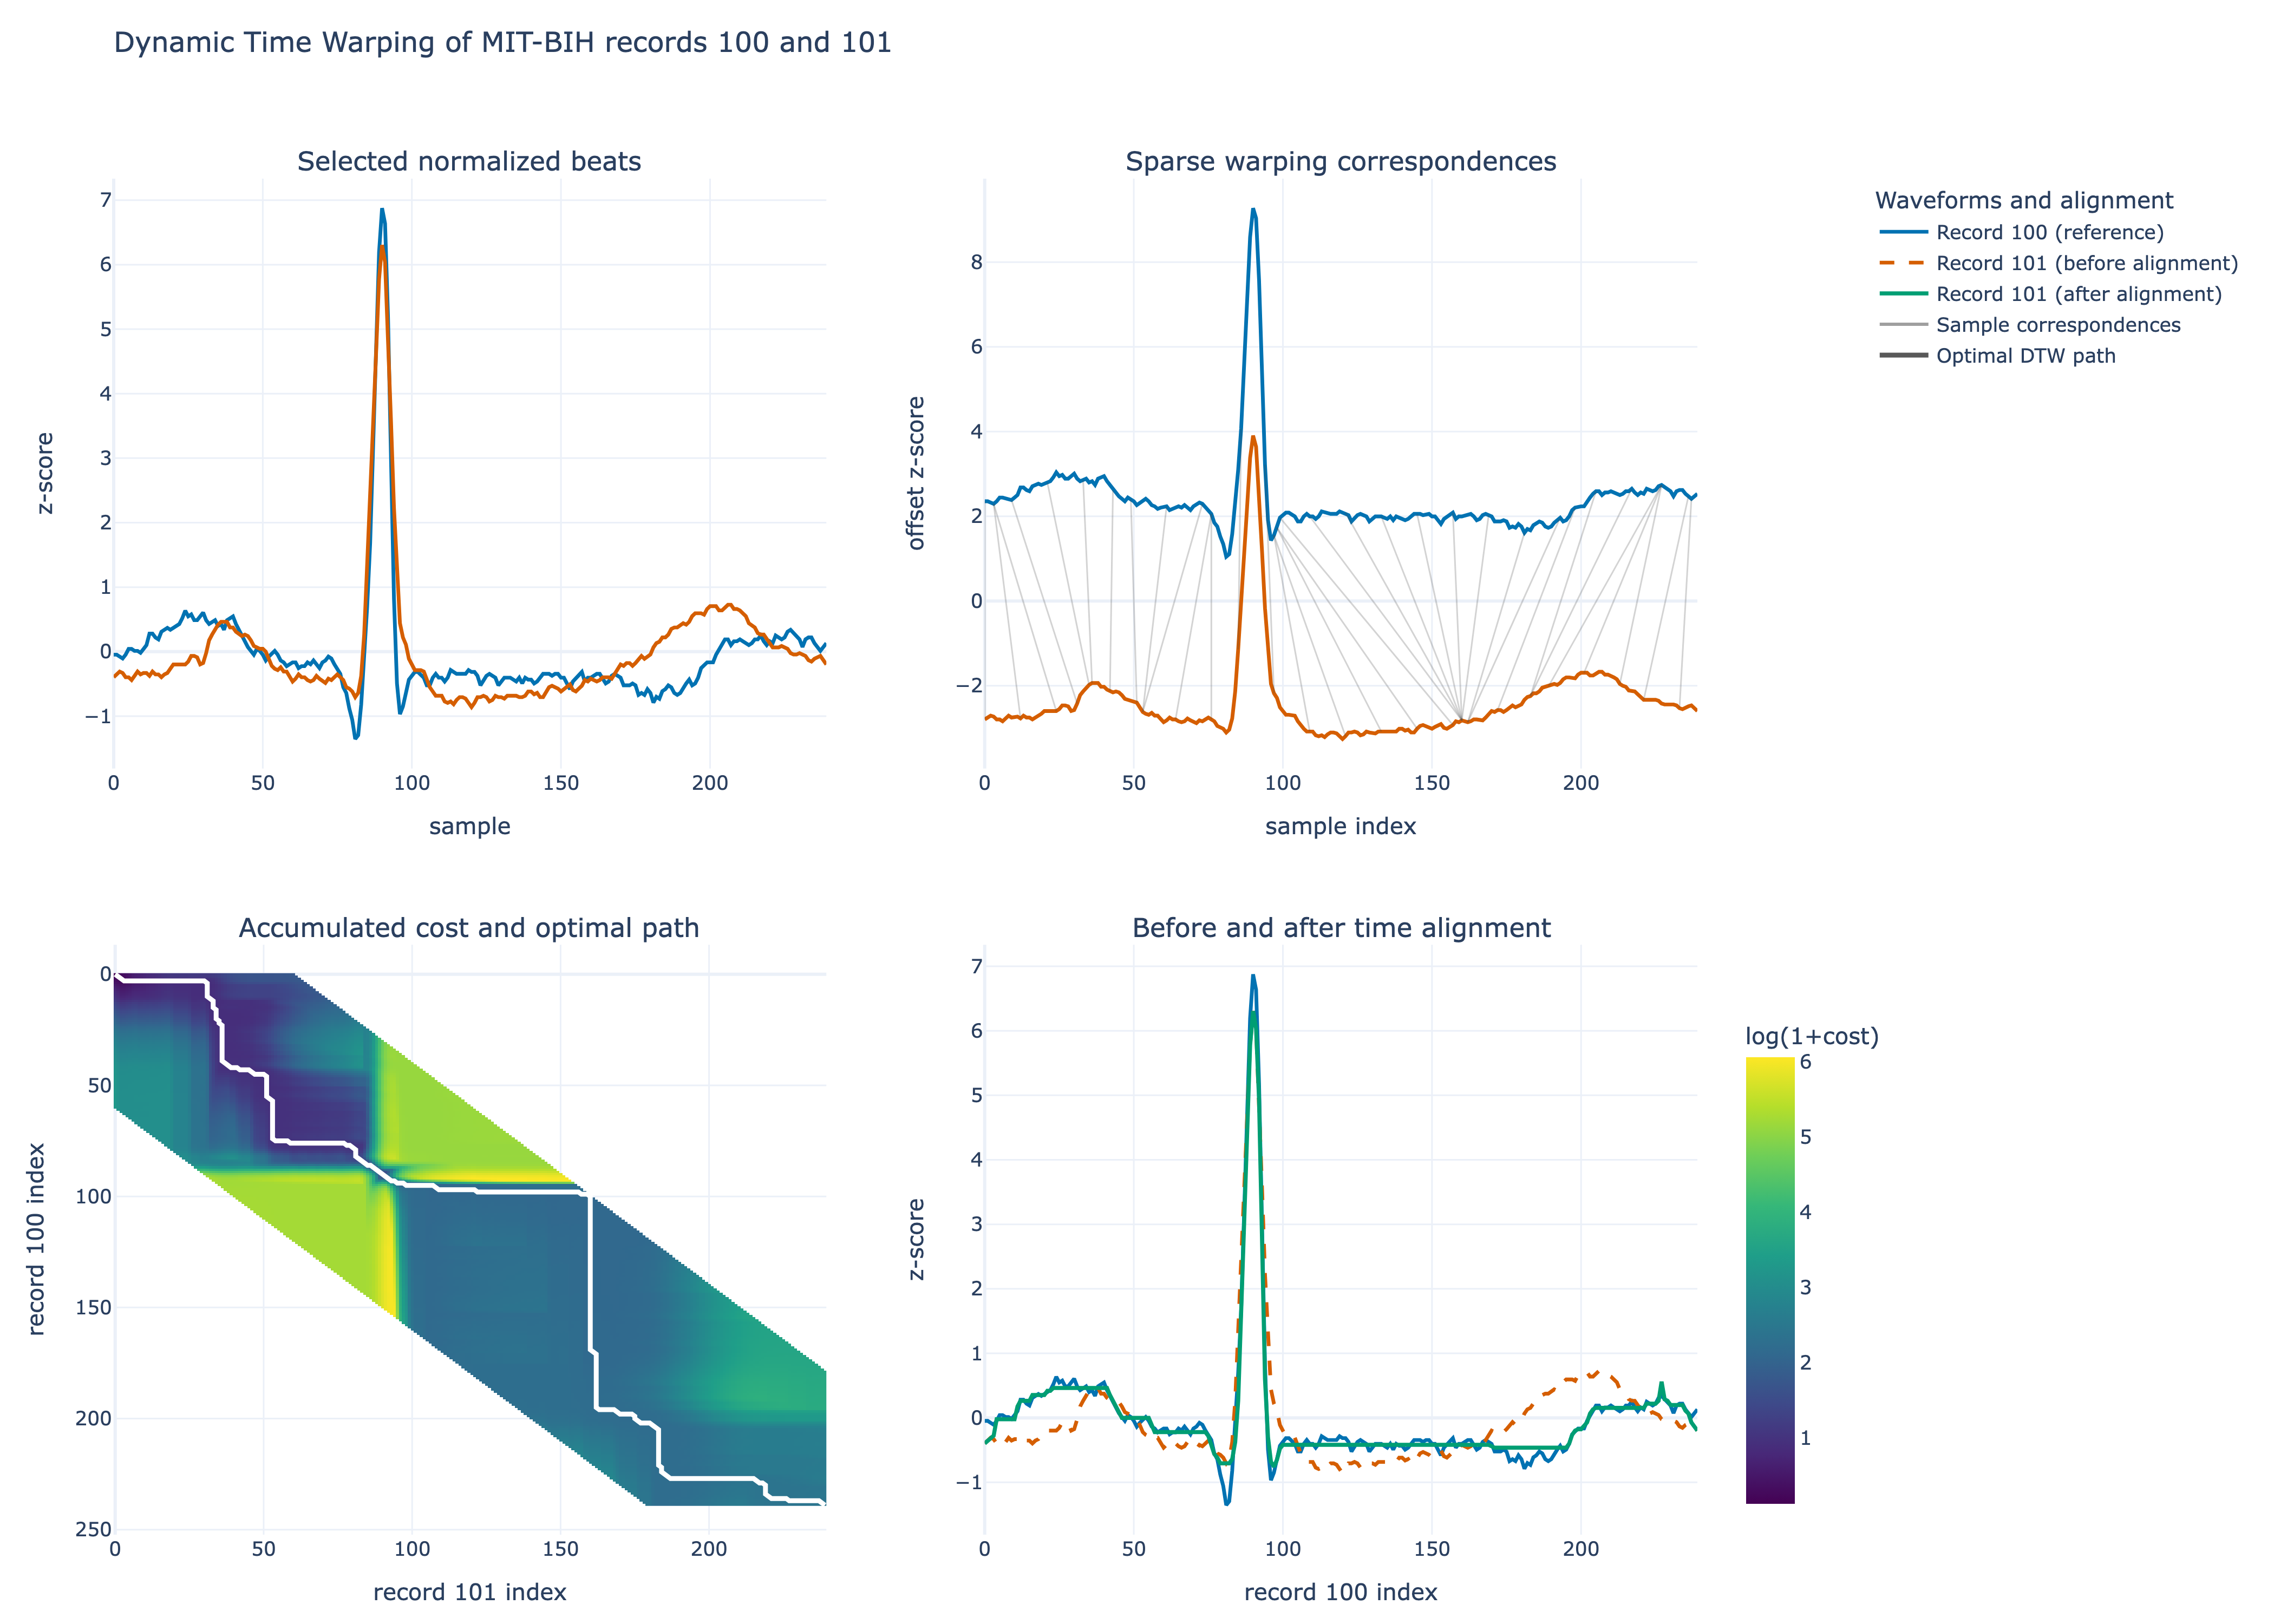

PosixPath('/Users/lopatenko/Desktop/itmo/itmo-ml-2025/tsml/lab-3/figures/mitbih_dtw.png')

In [14]:
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        "Selected normalized beats",
        "Sparse warping correspondences",
        "Accumulated cost and optimal path",
        "Before and after time alignment",
    ),
    vertical_spacing=0.13, horizontal_spacing=0.10,
)

wave_colors = {"reference": "#0072B2", "original": "#D55E00", "aligned": "#009E73"}

fig.add_trace(go.Scatter(y=beat_100, line=dict(color=wave_colors["reference"], width=2.3), showlegend=False), row=1, col=1)
fig.add_trace(go.Scatter(y=beat_101, line=dict(color=wave_colors["original"], width=2.3), showlegend=False), row=1, col=1)

fig.add_trace(go.Scatter(y=beat_100 + 2.4, line=dict(color=wave_colors["reference"], width=2.3), showlegend=False), row=1, col=2)
fig.add_trace(go.Scatter(y=beat_101 - 2.4, line=dict(color=wave_colors["original"], width=2.3), showlegend=False), row=1, col=2)
for i, j in warping_path[::12]:
    connection = go.Scatter(x=[i, j], y=[beat_100[i] + 2.4, beat_101[j] - 2.4], mode="lines", line=dict(color="rgba(80,80,80,0.25)", width=1), hoverinfo="skip", showlegend=False)
    fig.add_trace(connection, row=1, col=2)

fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines", name="Sample correspondences", legendrank=4,
                         line=dict(color="rgba(80,80,80,0.55)", width=2)), row=1, col=2)

path_i = [point[0] for point in warping_path]
path_j = [point[1] for point in warping_path]
cost_heatmap = go.Heatmap(z=np.log1p(accumulated_cost), colorscale="Viridis", colorbar=dict(title="log(1+cost)", len=0.38, y=0.20))
fig.add_trace(cost_heatmap, row=2, col=1)
fig.add_trace(go.Scatter(x=path_j, y=path_i, mode="lines", line=dict(color="white", width=3), name="DTW path", showlegend=False), row=2, col=1)
fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines", name="Optimal DTW path", legendrank=5,
                         line=dict(color="#595959", width=3)), row=2, col=1)

fig.add_trace(go.Scatter(y=beat_100, name="Record 100 (reference)", legendrank=1,
                         line=dict(color=wave_colors["reference"], width=2.3)), row=2, col=2)
fig.add_trace(go.Scatter(y=beat_101, name="Record 101 (before alignment)", legendrank=2,
                         line=dict(color=wave_colors["original"], width=2.3, dash="dash")), row=2, col=2)
fig.add_trace(go.Scatter(y=warped_101, name="Record 101 (after alignment)", legendrank=3,
                         line=dict(color=wave_colors["aligned"], width=2.5)), row=2, col=2)

fig.update_xaxes(title_text="sample", row=1, col=1)
fig.update_xaxes(title_text="sample index", row=1, col=2)
fig.update_xaxes(title_text="record 101 index", row=2, col=1)
fig.update_xaxes(title_text="record 100 index", row=2, col=2)
fig.update_yaxes(title_text="z-score", row=1, col=1)
fig.update_yaxes(title_text="offset z-score", row=1, col=2)
fig.update_yaxes(title_text="record 100 index", autorange="reversed", row=2, col=1)
fig.update_yaxes(title_text="z-score", row=2, col=2)
fig.update_layout(
    title="Dynamic Time Warping of MIT-BIH records 100 and 101",
    legend=dict(title_text="Waveforms and alignment", x=1.11, xanchor="left", y=1, yanchor="top"),
)
show_and_save(
    fig,
    "mitbih_dtw",
    "Four-panel DTW demonstration for MIT-BIH records 100 and 101: normalized beats, sparse sample correspondences, accumulated cost with optimal path, and the waveform before and after alignment.",
    height=1000,
    right_margin=355,
)


### Reading the alignment

DTW reduces the beat-to-beat RMSE from 0.4694 to 0.1312, a reduction of about **72%**. The aligned trace matches most closely around the sharp R peak and then compensates for timing differences in the surrounding P-QRS-T components.

The path contains 415 matched pairs for two 240-sample signals. Its substantial departure from the 240-step diagonal shows that the improvement requires local stretching rather than a simple global shift. The 60-sample Sakoe-Chiba window limits that flexibility, but the low warped RMSE should still be interpreted as alignment quality, not as proof that the two records have identical cardiac dynamics.


## 7. Conclusion

The three pairs separate three situations that can look similar in a correlation matrix. Actual and forecast load are nearly synchronous, with additional one-way predictive information from past actual demand at 2, 6 and 24 hours. SPY and QQQ are also synchronous, but neither provides corrected Granger evidence of a daily lead. The independent ECG groups show the main failure mode: repeated structure can produce strong Granger and CCM statistics even when a causal relation is impossible by construction.

Taken together, the analysis supports a directional predictive statement only for load, and even that statement belongs to the forecasting chronology rather than to a physical causal claim. For the other pairs, common structure—beat morphology for ECG and market-wide shocks for ETFs—explains the results more consistently than a stable lead-lag mechanism. DTW complements this analysis by showing that two ECG beats can be matched well after constrained local time deformation, reducing RMSE by about 72% while retaining the main waveform landmarks.
